# CricketLens: Exploratory Data Analysis and Prediction Models for the Men's IPL, 2008–2026

**Abstract.** This notebook analyses every men's Indian Premier League (IPL) match from 18 April 2008 to
31 May 2026 using Cricsheet ball-by-ball data. It rebuilds clean match, innings, over, delivery and batting
tables from the raw JSON files, validates them against known totals, audits data quality, and carries out
an exploratory data analysis of scoring, phases, the toss, innings order, venues, teams, players,
dismissals and boundaries, with statistical tests where they apply. It then builds two leakage-free
prediction tasks, compares seven algorithms in a chronological benchmark, examines the assumptions each
algorithm makes, selects the final model with a rule fixed in advance, and tests it on the 2026 season.

**Research questions.**
1. How have scoring, boundaries and results in the IPL changed from 2008 to 2026?
2. How do scoring and wickets differ between the powerplay, middle and death overs?
3. Are the toss and the choice to bat first or chase associated with winning?
4. How do venues, teams and players differ?
5. After a completed over, what is the probability that at least one wicket falls in the next over?
6. Before a match, what is the probability that a given batter scores 30+ and 50+ runs, given that they bat?
7. Which of seven algorithms gives the best-calibrated probabilities for questions 5 and 6, which of their
   assumptions hold, and does the comparison stabilise as more history is used?

**How to run.** Set `DATA_DIR` (next cell) to a folder of Cricsheet IPL JSON files; by default it is
`../data/raw/ipl_json` relative to this notebook. Run all cells from top to bottom. Only matches dated on
or before 2026-05-31 are used, so results reproduce even if newer matches are downloaded later.
Library versions are printed in the first code cell. The total execution time on the development machine
is recorded here after execution: **about 6.4 minutes (one top-to-bottom run with nbconvert, Python 3.14, Windows laptop)**. The longest part is the model benchmark
in Section 9.

In [1]:
import io
import json
import math
import platform
import time
import warnings
from collections import defaultdict
from datetime import date
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
from IPython.display import Image, display  # noqa: E402

NOTEBOOK_START = time.perf_counter()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print("Python", platform.python_version())
for lib in (np, pd, scipy, sklearn, matplotlib):
    print(f"{lib.__name__:>12} {lib.__version__}")


def show(fig):
    """Render a figure as a compact PNG and close it."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    plt.close(fig)
    display(Image(buffer.getvalue()))

Python 3.14.7
       numpy 2.5.4
      pandas 2.3.3
       scipy 1.18.1
     sklearn 1.8.0
  matplotlib 3.11.2


## 1. Data source and licence

All match data comes from [Cricsheet](https://cricsheet.org/), which publishes structured ball-by-ball data
for the IPL as one JSON file per match. Cricsheet data is made available under the Open Data Commons
Attribution License (ODC-By 1.0). **Credit: match data from Cricsheet (https://cricsheet.org/).**

If the folder below does not exist, download the IPL JSON archive from
<https://cricsheet.org/downloads/ipl_json.zip>, unzip it, and set `DATA_DIR` to the folder that contains
the `.json` files.

In [2]:
NOTEBOOK_DIR = Path.cwd()
DATA_DIR = Path("..") / "data" / "raw" / "ipl_json"
CUTOFF = date(2026, 5, 31)            # the analysis is fixed to matches up to this date
REPO = Path("..")                     # optional: the project repository, for cross-checks
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Cricsheet IPL JSON folder not found. Download https://cricsheet.org/downloads/ipl_json.zip, "
        "unzip it and set DATA_DIR to that folder.")
files = sorted(DATA_DIR.glob("*.json"))
print(f"{len(files):,} JSON files in {DATA_DIR.as_posix()}")

1,243 JSON files in ../data/raw/ipl_json


## 2. Data preparation and cleaning

Each file holds one match: `info` (teams, date, venue, toss, outcome, player registry) and `innings`, each
with overs and deliveries. The cleaning rules, applied while parsing:

- **Legal balls.** A wide or a no-ball is not a legal delivery. A no-ball is faced by the batter; a wide is
  not.
- **Super overs** decide a tied match but are not part of the ordinary match: their innings are skipped in
  every table, and the Super Over winner is kept as the match's final winner.
- **Outcomes.** A match is decided in regulation, by a Super Over, or ends with no result. A D/L-marked
  result is flagged (`outcome_method`).
- **Franchise renames** are merged (Delhi Daredevils → Delhi Capitals, Kings XI Punjab → Punjab Kings,
  Royal Challengers Bangalore → Royal Challengers Bengaluru, Rising Pune Supergiants → Rising Pune
  Supergiant). Deccan Chargers and Sunrisers Hyderabad, and Gujarat Lions and Gujarat Titans, stay separate.
- **Venues** with several spellings of the same ground are mapped to one canonical name.
- **Team wickets** count every dismissal except *retired hurt* and *retired not out*. **Bowler-credited
  wickets** are bowled, caught, caught and bowled, lbw, stumped and hit wicket.
- **Boundaries.** A four or six off the bat is a boundary unless Cricsheet flags it `non_boundary` (for
  example an all-run four).
- **Batting innings** include a non-striker who was run out without facing a ball.

In [3]:
RENAMES = {"Delhi Daredevils": "Delhi Capitals", "Kings XI Punjab": "Punjab Kings",
           "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
           "Rising Pune Supergiants": "Rising Pune Supergiant"}
VENUE_ALIASES = {
    "Eden Gardens, Kolkata": "Eden Gardens", "Wankhede Stadium, Mumbai": "Wankhede Stadium",
    "M Chinnaswamy Stadium, Bengaluru": "M Chinnaswamy Stadium", "M.Chinnaswamy Stadium": "M Chinnaswamy Stadium",
    "MA Chidambaram Stadium": "MA Chidambaram Stadium, Chepauk",
    "MA Chidambaram Stadium, Chepauk, Chennai": "MA Chidambaram Stadium, Chepauk",
    "Rajiv Gandhi International Stadium": "Rajiv Gandhi International Stadium, Uppal",
    "Rajiv Gandhi International Stadium, Uppal, Hyderabad": "Rajiv Gandhi International Stadium, Uppal",
    "Sawai Mansingh Stadium, Jaipur": "Sawai Mansingh Stadium", "Feroz Shah Kotla": "Arun Jaitley Stadium",
    "Arun Jaitley Stadium, Delhi": "Arun Jaitley Stadium",
    "Punjab Cricket Association Stadium, Mohali": "Punjab Cricket Association IS Bindra Stadium, Mohali",
    "Punjab Cricket Association IS Bindra Stadium": "Punjab Cricket Association IS Bindra Stadium, Mohali",
    "Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh": "Punjab Cricket Association IS Bindra Stadium, Mohali",
    "Zayed Cricket Stadium, Abu Dhabi": "Sheikh Zayed Stadium",
    "Maharashtra Cricket Association Stadium, Pune": "Maharashtra Cricket Association Stadium",
    "Dr DY Patil Sports Academy, Mumbai": "Dr DY Patil Sports Academy", "Brabourne Stadium, Mumbai": "Brabourne Stadium",
    "Himachal Pradesh Cricket Association Stadium, Dharamsala": "Himachal Pradesh Cricket Association Stadium",
    "Shaheed Veer Narayan Singh International Stadium, Raipur": "Shaheed Veer Narayan Singh International Stadium",
    "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam": "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium",
    "Maharaja Yadavindra Singh International Cricket Stadium, New Chandigarh": "Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur",
}
NO_TEAM_WICKET = {"retired hurt", "retired not out"}
BOWLER_CREDITED = {"bowled", "caught", "caught and bowled", "lbw", "stumped", "hit wicket"}
franchise = lambda name: RENAMES.get(name, name)  # noqa: E731
venue_name = lambda raw: VENUE_ALIASES.get(raw, raw)  # noqa: E731


def parse_archive(paths, cutoff):
    """One pass over the JSON files: matches, innings, overs, deliveries, batter innings and dismissals."""
    matches, innings_rows, overs, deliveries, batters, dismissals = [], [], [], [], [], []
    super_over_innings_total, skipped_after_cutoff = 0, 0
    for path in paths:
        match = json.loads(path.read_text(encoding="utf-8"))
        info = match["info"]
        match_date = date.fromisoformat(str(info["dates"][0])[:10])
        if match_date > cutoff:
            skipped_after_cutoff += 1
            continue
        match_id = path.stem
        teams = [franchise(t) for t in info["teams"]]
        registry = (info.get("registry") or {}).get("people") or {}
        outcome = info.get("outcome") or {}
        eliminator = franchise(outcome["eliminator"]) if outcome.get("eliminator") else ""
        winner = franchise(outcome["winner"]) if outcome.get("winner") else ""
        result = "tie" if outcome.get("result") == "tie" or eliminator else outcome.get("result", "win" if winner else "unknown")
        super_overs = sum(inn.get("super_over") is True for inn in match["innings"])
        super_over_innings_total += super_overs
        toss = info.get("toss") or {}
        venue = info.get("venue") or ""
        matches.append({
            "match_id": match_id, "date": match_date.isoformat(), "season": match_date.year,
            "team1": teams[0], "team2": teams[1], "venue": venue, "venue_canonical": venue_name(venue),
            "city": info.get("city") or "", "event": (info.get("event") or {}).get("name", ""),
            "gender": info.get("gender", ""), "winner": winner, "outcome_type": result,
            "regulation_result": result, "final_winner": winner or eliminator, "super_over_winner": eliminator,
            "super_over_innings": super_overs,
            "decided_by": "super_over" if eliminator else "regulation" if winner else "no_result",
            "outcome_method": outcome.get("method", ""),
            "toss_winner": franchise(toss["winner"]) if toss.get("winner") else "",
            "toss_decision": toss.get("decision", ""),
        })
        for position, inn in enumerate(match["innings"], start=1):
            if inn.get("super_over") is True:
                continue
            batting = franchise(inn["team"])
            bowling = teams[1] if batting == teams[0] else teams[0]
            total, wickets, legal_total = 0, 0, 0
            runs_by, balls_by, out_by = defaultdict(int), defaultdict(int), defaultdict(int)
            over_count = 0
            for over in inn.get("overs") or []:
                number, legal = over["over"], 0
                for k, ball in enumerate(over.get("deliveries") or [], start=1):
                    r, extras = ball.get("runs") or {}, ball.get("extras") or {}
                    is_legal = "wides" not in extras and "noballs" not in extras
                    legal += is_legal
                    legal_total += is_legal
                    total += int(r.get("total", 0))
                    batter = ball.get("batter", "")
                    runs_by[batter] += int(r.get("batter", 0))
                    balls_by[batter] += int("wides" not in extras)
                    team_wickets = 0
                    for w in ball.get("wickets") or []:
                        kind = w.get("kind", "").lower()
                        if kind not in NO_TEAM_WICKET:
                            team_wickets += 1
                            out_by[w.get("player_out", "")] += 1
                        dismissals.append({
                            "match_id": match_id, "season": match_date.year, "innings": position,
                            "batting_team": batting, "bowling_team": bowling, "over_index": number,
                            "kind": kind, "player_out": w.get("player_out", ""),
                            "player_out_id": registry.get(w.get("player_out", ""), ""),
                            "batter": batter, "non_striker": ball.get("non_striker", ""),
                            "bowler": ball.get("bowler", ""), "bowler_id": registry.get(ball.get("bowler", ""), ""),
                            "team_wicket": kind not in NO_TEAM_WICKET, "bowler_credited": kind in BOWLER_CREDITED})
                    wickets += team_wickets
                    deliveries.append({
                        "match_id": match_id, "date": match_date.isoformat(), "season": match_date.year,
                        "innings": position, "batting_team": batting, "bowling_team": bowling,
                        "over_index": number, "delivery_index": k, "batter": batter,
                        "batter_id": registry.get(batter, ""), "bowler": ball.get("bowler", ""),
                        "runs_batter": int(r.get("batter", 0)), "runs_extras": int(r.get("extras", 0)),
                        "runs_total": int(r.get("total", 0)), "wides": int(extras.get("wides", 0)),
                        "noballs": int(extras.get("noballs", 0)), "byes": int(extras.get("byes", 0)),
                        "legbyes": int(extras.get("legbyes", 0)), "legal_delivery": int(is_legal),
                        "team_wickets_on_ball": team_wickets, "innings_runs_after": total,
                        "innings_wickets_after": wickets,
                        # Extra fields for the EDA (not in the project's processed delivery table)
                        "non_striker": ball.get("non_striker", ""),
                        "non_striker_id": registry.get(ball.get("non_striker", ""), ""),
                        "bowler_id": registry.get(ball.get("bowler", ""), ""),
                        "non_boundary": bool(r.get("non_boundary", False))})
                over_count += 1
                overs.append({"match_id": match_id, "date": match_date.isoformat(), "season": match_date.year,
                              "innings": position, "batting_team": batting, "bowling_team": bowling,
                              "over_index": number, "legal_balls": legal, "runs_after": total,
                              "wickets_after": wickets, "complete_standard_over": int(legal == 6)})
            innings_rows.append({"match_id": match_id, "date": match_date.isoformat(), "season": match_date.year,
                                 "innings": position, "batting_team": batting, "bowling_team": bowling,
                                 "venue": venue, "venue_canonical": venue_name(venue), "runs": total,
                                 "wickets": wickets, "legal_balls": legal_total, "overs_recorded": over_count})
            for name, runs in runs_by.items():
                batters.append({"match_id": match_id, "date": match_date.isoformat(), "season": match_date.year,
                                "innings": position, "batting_team": batting, "bowling_team": bowling,
                                "venue": venue, "venue_canonical": venue_name(venue), "batter": name,
                                "batter_id": registry.get(name, ""), "runs": runs, "balls_faced": balls_by[name],
                                "dismissed": int(bool(out_by[name])), "reached_30": int(runs >= 30),
                                "reached_50": int(runs >= 50)})
    frames = {name: pd.DataFrame(rows) for name, rows in (
        ("matches", matches), ("innings", innings_rows), ("overs", overs), ("deliveries", deliveries),
        ("batter_innings", batters), ("dismissals", dismissals))}
    return frames, super_over_innings_total, skipped_after_cutoff


def through_csv(frame, **read_args):
    """Write a table to CSV text and read it back, as the project's stored tables are."""
    return pd.read_csv(io.StringIO(frame.to_csv(index=False)), **read_args)


raw, SUPER_OVER_INNINGS, AFTER_CUTOFF = parse_archive(files, CUTOFF)
tables = {name: through_csv(frame) for name, frame in raw.items()}
matches, innings, overs, deliveries, batter_innings, dismissals = (
    tables[k] for k in ("matches", "innings", "overs", "deliveries", "batter_innings", "dismissals"))
print(f"Matches after the cutoff skipped: {AFTER_CUTOFF}")
print({name: len(frame) for name, frame in tables.items()})

Matches after the cutoff skipped: 0
{'matches': 1243, 'innings': 2480, 'overs': 47756, 'deliveries': 295557, 'batter_innings': 18768, 'dismissals': 14674}


**Validation against the verified totals.** The assertions below fail if any count differs from the
figures verified for this archive.

In [4]:
legal = deliveries.legal_delivery == 1
checks = {
    "matches": (len(matches), 1243),
    "deliveries": (len(deliveries), 295557),
    "legal deliveries": (int(legal.sum()), 284465),
    "runs": (int(deliveries.runs_total.sum()), 401423),
    "team wickets": (int(deliveries.team_wickets_on_ball.sum()), 14655),
    "seasons": (matches.season.nunique(), 19),
    "first match": (matches.date.min(), "2008-04-18"),
    "last match": (matches.date.max(), "2026-05-31"),
}
for name, (got, expected) in checks.items():
    assert got == expected, (name, got, expected)
    print(f"{name:>16}: {got:,}" if isinstance(got, int) else f"{name:>16}: {got}")
assert set(matches.gender) == {"male"} and set(matches.event) == {"Indian Premier League"}
print("Super-over innings left out of every table:", SUPER_OVER_INNINGS)
print("All verified totals match.")

         matches: 1,243
      deliveries: 295,557
legal deliveries: 284,465
            runs: 401,423
    team wickets: 14,655
         seasons: 19
     first match: 2008-04-18
      last match: 2026-05-31
Super-over innings left out of every table: 34
All verified totals match.


The rebuilt tables match every verified total: 1,243 matches over 19 seasons, 295,557 delivery records of
which 284,465 are legal balls, 401,423 runs and 14,655 team wickets.

**Optional cross-check.** When the project's processed tables are present (`../data/processed`), the cell
below checks that the notebook's tables are identical to them, column by column. It is skipped otherwise.

In [5]:
PROCESSED = REPO / "data" / "processed"
KEYS = {"matches": ["match_id"], "innings": ["match_id", "innings"], "overs": ["match_id", "innings", "over_index"],
        "deliveries": ["match_id", "innings", "over_index", "delivery_index"],
        "batter_innings": ["match_id", "innings", "batter_id"]}
if PROCESSED.is_dir():
    for name, key in KEYS.items():
        stored = pd.read_csv(PROCESSED / f"{name}.csv")
        mine = tables[name][stored.columns]
        pd.testing.assert_frame_equal(stored.sort_values(key).reset_index(drop=True),
                                      mine.sort_values(key).reset_index(drop=True), check_dtype=False)
        print(f"{name:>15}: identical to data/processed ({len(stored):,} rows)")
else:
    print("Project tables not found; cross-check skipped.")

        matches: identical to data/processed (1,243 rows)
        innings: identical to data/processed (2,480 rows)
          overs: identical to data/processed (47,756 rows)


     deliveries: identical to data/processed (295,557 rows)
 batter_innings: identical to data/processed (18,768 rows)


## 3. Data quality audit

Missing values, anomalies, data types and the measurement scale of the main fields.

In [6]:
missing = matches.replace("", np.nan).isna().sum()
print("Missing values in the match table (blank fields):")
print(missing[missing > 0].to_string())
print("\nOutcome methods:", matches.outcome_method.fillna("(none)").value_counts().to_dict())
print("Decided by:", matches.decided_by.value_counts().to_dict())
anomalies = {"overs with more than six legal balls": int((overs.legal_balls > 6).sum()),
             "recorded overs with no legal ball": int((overs.legal_balls == 0).sum()),
             "innings with fewer than 120 legal balls": int((innings.legal_balls < 120).sum()),
             "deliveries without a batter ID": int((deliveries.batter_id.fillna("") == "").sum())}
for k, v in anomalies.items():
    print(f"{k}: {v:,}")

Missing values in the match table (blank fields):
city                   51
winner                 25
final_winner            9
super_over_winner    1227
outcome_method       1220

Outcome methods: {'(none)': 1220, 'D/L': 23}
Decided by: {'regulation': 1218, 'super_over': 16, 'no_result': 9}
overs with more than six legal balls: 4
recorded overs with no legal ball: 4
innings with fewer than 120 legal balls: 868
deliveries without a batter ID: 0


The match table is complete apart from a few fields that are blank by design: the regulation `winner` is
blank for Super Over and no-result matches, `outcome_method` is blank unless the D/L method was used, and a
few matches have no city. A handful of recorded overs have an unusual number of legal balls (scorer
records kept as published); they are counted above and handled by the eligibility rules of Section 5.

In [7]:
scales = pd.DataFrame([
    ("season", "int", "interval (calendar year)"), ("date", "date", "interval"),
    ("team1 / team2 / batting_team / bowling_team", "text", "nominal"), ("venue_canonical", "text", "nominal"),
    ("toss_decision", "text", "nominal (bat / field)"), ("decided_by", "text", "nominal"),
    ("runs, wickets, legal balls, balls faced", "int", "ratio (counts)"),
    ("run rate, strike rate, economy", "float", "ratio"), ("over_index / phase", "int / text", "ordinal"),
    ("milestone class (<30, 30–49, 50+)", "int", "ordinal"),
], columns=["field", "type", "measurement scale"])
display(scales)
print(deliveries.dtypes.value_counts().to_dict())

,field,type,measurement scale
0,season,int,interval (calendar year)
1,date,date,interval
2,team1 / team2 / batting_team / bowling_team,text,nominal
3,venue_canonical,text,nominal
4,toss_decision,text,nominal (bat / field)
5,decided_by,text,nominal
6,"runs, wickets, legal balls, balls faced",int,ratio (counts)
7,"run rate, strike rate, economy",float,ratio
8,over_index / phase,int / text,ordinal
9,"milestone class (<30, 30–49, 50+)",int,ordinal


{dtype('int64'): 16, dtype('O'): 9, dtype('bool'): 1}


Counts such as runs and wickets are ratio-scale (zero means none, and ratios are meaningful), so means and
rates are appropriate. Teams, venues and toss decisions are nominal and are compared by counts and shares,
never averaged. Phase is ordinal (powerplay, middle, death).

## 4. Exploratory data analysis (2008–2026)

All descriptive results use the full history. Matches decided by a Super Over count as wins for the Super
Over winner; no-result matches are left out of win percentages. The results describe what happened: they
are observational and do not by themselves show causes.

### 4.1 Season trends

Matches, runs, run rate (runs per six legal balls) and boundaries per match for every season.

,matches,runs,run_rate,fours,sixes,boundaries_per_match
season,,,,,,
2008,58,17937,8.3100,1703,622,40.0900
2009,57,16320,7.4800,1316,506,31.9600
2010,60,18864,8.1300,1708,585,38.2200
2011,73,21154,7.7300,1913,639,34.9600
2012,74,22453,7.8300,1911,731,35.7000
2013,76,22541,7.6800,2051,674,35.8600
2014,60,18909,8.2000,1562,714,37.9300
2015,59,18332,8.3700,1607,692,38.9700
2016,60,18862,8.3100,1632,638,37.8300


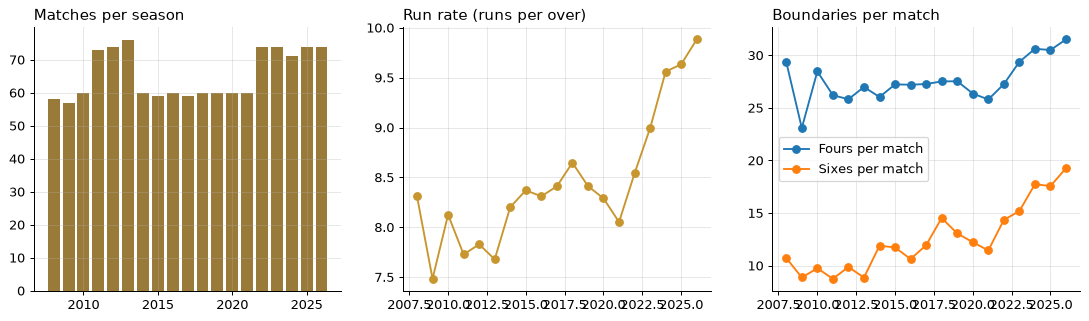

Run rate: 8.31 in 2008, 9.88 in 2026; highest 9.88 in 2026.
Sixes per match: 10.7 in 2008, 19.3 in 2026.


In [8]:
d = deliveries.copy()
d["is_four"] = (d.runs_batter == 4) & ~d.non_boundary
d["is_six"] = (d.runs_batter == 6) & ~d.non_boundary
d["phase"] = pd.cut(d.over_index, [-1, 5, 15, 19], labels=["powerplay", "middle", "death"])
season = d.groupby("season").agg(runs=("runs_total", "sum"), legal=("legal_delivery", "sum"),
                                 fours=("is_four", "sum"), sixes=("is_six", "sum"))
season["matches"] = matches.groupby("season").size()
season["run_rate"] = season.runs / (season.legal / 6)
season["boundaries_per_match"] = (season.fours + season.sixes) / season.matches
season["sixes_per_match"] = season.sixes / season.matches
display(season[["matches", "runs", "run_rate", "fours", "sixes", "boundaries_per_match"]].round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(season.index, season.matches, color="#9A7A38")
axes[0].set_title("Matches per season", loc="left")
axes[1].plot(season.index, season.run_rate, marker="o", color="#C8962E")
axes[1].set_title("Run rate (runs per over)", loc="left")
axes[2].plot(season.index, season.fours / season.matches, marker="o", label="Fours per match")
axes[2].plot(season.index, season.sixes_per_match, marker="o", label="Sixes per match")
axes[2].set_title("Boundaries per match", loc="left")
axes[2].legend()
show(fig)
first, last = season.index.min(), season.index.max()
peak = season.run_rate.idxmax()
print(f"Run rate: {season.run_rate[first]:.2f} in {first}, {season.run_rate[last]:.2f} in {last}; "
      f"highest {season.run_rate[peak]:.2f} in {peak}.")
print(f"Sixes per match: {season.sixes_per_match[first]:.1f} in {first}, {season.sixes_per_match[last]:.1f} in {last}.")

Scoring was broadly stable for the first fifteen seasons and then rose sharply from 2023 onwards, with both
the run rate and the number of sixes per match reaching their highest values in the latest seasons. Any
analysis or model that pools all seasons has to allow for this shift (Section 6 measures it).

### 4.2 First-innings score distribution

Only **completed** first innings are used: the second innings started, ten wickets fell, or 120 legal balls
were bowled. A first innings ended by rain with no second innings would understate the typical total.

Completed first innings: 1,239 of 1,243 (4 left out).
count   1,239.0000
mean      168.8000
std        33.7000
min        62.0000
25%       148.0000
50%       168.0000
75%       190.0000
max       287.0000


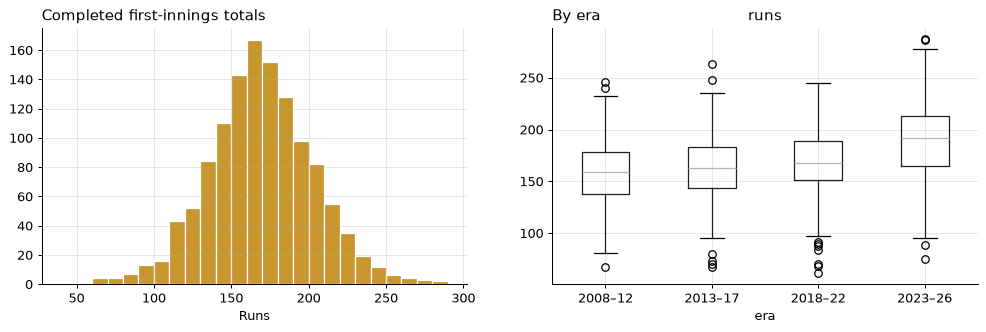

         count     mean   median
season                          
2008–12    321 157.4000 159.0000
2013–17    314 162.4000 162.5000
2018–22    314 168.0000 168.0000
2023–26    290 189.5000 192.0000


In [9]:
first_inn = innings[innings.innings == 1].copy()
has_second = first_inn.match_id.isin(innings.loc[innings.innings == 2, "match_id"])
first_inn["completed"] = has_second | (first_inn.wickets == 10) | (first_inn.legal_balls >= 120)
complete_first = first_inn[first_inn.completed]
print(f"Completed first innings: {len(complete_first):,} of {len(first_inn):,} "
      f"({(~first_inn.completed).sum()} left out).")
desc = complete_first.runs.describe(percentiles=[.25, .5, .75])
print(desc.round(1).to_string())
eras = pd.cut(complete_first.season, [2007, 2012, 2017, 2022, 2026], labels=["2008–12", "2013–17", "2018–22", "2023–26"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(complete_first.runs, bins=range(40, 300, 10), color="#C8962E", edgecolor="white")
axes[0].set_title("Completed first-innings totals", loc="left")
axes[0].set_xlabel("Runs")
complete_first.assign(era=eras).boxplot(column="runs", by="era", ax=axes[1])
axes[1].set_title("By era", loc="left")
fig.suptitle("")
show(fig)
print(complete_first.groupby(eras, observed=True).runs.agg(["count", "mean", "median"]).round(1).to_string())

Completed first-innings totals are roughly bell-shaped with a slightly longer right tail. The era medians
show the same shift as Section 4.1: totals in 2023–26 sit well above the earlier eras.

### 4.3 Phases of the innings

Powerplay is overs 1–6, the middle overs 7–16 and the death overs 17–20. The uncertainty of the death-minus-
powerplay difference in run rate is estimated with a **bootstrap clustered by match** (whole matches are
resampled, because deliveries within a match are not independent).

,runs,legal,wickets,run_rate,wickets_per_over
phase,,,,,
powerplay,120188,89153,3575,8.0890,0.2410
middle,195514,145546,6541,8.0600,0.2700
death,85721,49766,4539,10.3350,0.5470


Death minus powerplay run rate, mean over 2,305 innings in 1,218 matches: 2.35 runs per over (95% cluster-bootstrap interval 2.19 to 2.53).


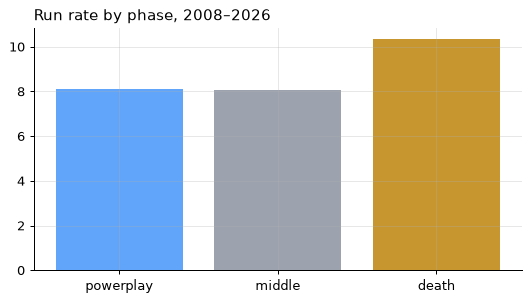

In [10]:
phase = d.groupby("phase", observed=True).agg(runs=("runs_total", "sum"), legal=("legal_delivery", "sum"),
                                              wickets=("team_wickets_on_ball", "sum"))
phase["run_rate"] = phase.runs / (phase.legal / 6)
phase["wickets_per_over"] = phase.wickets / (phase.legal / 6)
display(phase.round(3))
# Innings that reached the death overs: powerplay and death run rates per innings
per = d.groupby(["match_id", "innings", "phase"], observed=True).agg(runs=("runs_total", "sum"), legal=("legal_delivery", "sum")).unstack("phase")
per = per[(per["legal"]["powerplay"] > 0) & (per["legal"]["death"] > 0)]
diff = per["runs"]["death"] / (per["legal"]["death"] / 6) - per["runs"]["powerplay"] / (per["legal"]["powerplay"] / 6)
by_match = diff.groupby(level="match_id")
match_ids = np.array(list(by_match.groups))
sums, counts = by_match.sum().loc[match_ids].to_numpy(), by_match.size().loc[match_ids].to_numpy()
rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    pick = rng.integers(0, len(match_ids), len(match_ids))
    boot.append(sums[pick].sum() / counts[pick].sum())
low, high = np.percentile(boot, [2.5, 97.5])
print(f"Death minus powerplay run rate, mean over {len(diff):,} innings in {len(match_ids):,} matches: "
      f"{diff.mean():.2f} runs per over (95% cluster-bootstrap interval {low:.2f} to {high:.2f}).")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(phase.index.astype(str), phase.run_rate, color=["#60A5FA", "#9CA3AF", "#C8962E"])
ax.set_title("Run rate by phase, 2008–2026", loc="left")
show(fig)

Scoring is fastest at the death; the powerplay and middle overs score at almost the same rate. Wickets
also fall most often at the death, when batters take more risks. The bootstrap interval for the death-minus-powerplay difference excludes zero,
so the gap is not explained by match-to-match variation in this archive.

### 4.4 The toss

How often toss winners chose to field, and whether the toss winner went on to win. The association between
the toss decision and the toss winner's result is tested with Fisher's exact test and a chi-square test on
decided matches.

Toss winners chose to field in 66.4% of 1,243 matches (35% in 2010 to 83% in 2018).
Toss winners won 51.4% of 1,234 decided matches (binomial test against 50%: p = 0.348).


toss_winner_won,toss winner lost,toss winner won
toss_decision,,
bat,226,188
field,374,446


Fisher's exact test: odds ratio 1.43, p = 0.003; chi-square = 8.52, p = 0.004.


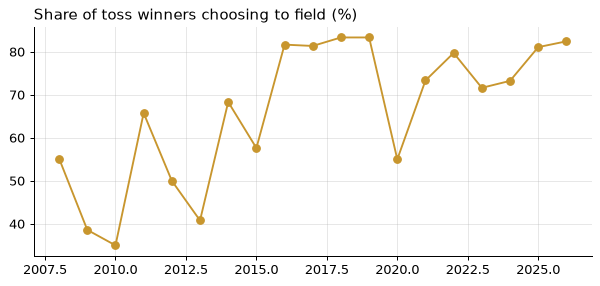

In [11]:
decided = matches[matches.final_winner.notna()].copy()
decided["toss_winner_won"] = decided.toss_winner == decided.final_winner
by_season = matches.groupby("season").apply(lambda g: (g.toss_decision == "field").mean(), include_groups=False)
print(f"Toss winners chose to field in {(matches.toss_decision == 'field').mean():.1%} of {len(matches):,} matches "
      f"({by_season.min():.0%} in {by_season.idxmin()} to {by_season.max():.0%} in {by_season.idxmax()}).")
rate = decided.toss_winner_won.mean()
binom = stats.binomtest(int(decided.toss_winner_won.sum()), len(decided), 0.5)
print(f"Toss winners won {rate:.1%} of {len(decided):,} decided matches (binomial test against 50%: p = {binom.pvalue:.3f}).")
table = pd.crosstab(decided.toss_decision, decided.toss_winner_won)
odds, fisher_p = stats.fisher_exact(table.to_numpy())
chi2, chi_p, dof, _ = stats.chi2_contingency(table.to_numpy())
display(table.rename(columns={False: "toss winner lost", True: "toss winner won"}))
print(f"Fisher's exact test: odds ratio {odds:.2f}, p = {fisher_p:.3f}; chi-square = {chi2:.2f}, p = {chi_p:.3f}.")
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(by_season.index, by_season.values * 100, marker="o", color="#C8962E")
ax.set_title("Share of toss winners choosing to field (%)", loc="left")
show(fig)

Fielding first became the usual choice from 2016 onwards. Winning the toss on its own is not clearly
associated with winning: the toss winners' win rate is close to 50% and the binomial test does not reject
50%. The decision matters more: toss winners who chose to field won noticeably more often than those who
chose to bat (Fisher's test above), which is consistent with the chasing advantage in Section 4.5. These
are associations; the decision is chosen by the captains, not assigned at random.

### 4.5 Batting first or chasing

Chasing teams won 54.5% of 1,234 decided matches (binomial test against 50%: p = 0.0019); seasons where chasing won more than half: 14 of 19.


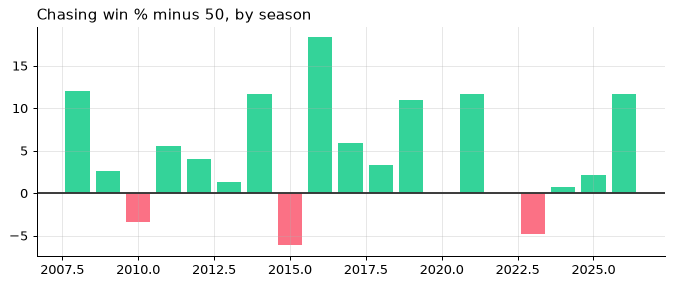

In [12]:
first_bat = innings[innings.innings == 1].set_index("match_id").batting_team
dm = decided.set_index("match_id")
dm["first_batting"] = first_bat.reindex(dm.index)
dm = dm[dm.first_batting.notna()]
dm["chaser_won"] = dm.final_winner != dm.first_batting
chase = dm.groupby("season").chaser_won.mean()
test = stats.binomtest(int(dm.chaser_won.sum()), len(dm), 0.5)
print(f"Chasing teams won {dm.chaser_won.mean():.1%} of {len(dm):,} decided matches (binomial test against 50%: "
      f"p = {test.pvalue:.4f}); seasons where chasing won more than half: {(chase > 0.5).sum()} of {len(chase)}.")
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.bar(chase.index, chase.values * 100 - 50, color=np.where(chase.values > .5, "#34D399", "#FB7185"))
ax.axhline(0, color="#333")
ax.set_title("Chasing win % minus 50, by season", loc="left")
show(fig)

Over the whole archive chasing teams have won more often than teams batting first, and the binomial test
shows the difference is unlikely to be chance alone; the advantage varies from season to season and
reverses in some.

### 4.6 Venues

Venues that hosted at least 20 matches: mean completed first-innings total and the chasing team's win rate.

In [13]:
venue = complete_first.groupby("venue_canonical").agg(first_innings_mean=("runs", "mean"))
venue["matches"] = matches.groupby("venue_canonical").size()
venue["chase_win_pct"] = dm.groupby("venue_canonical").chaser_won.mean() * 100
venue = venue[venue.matches >= 20].sort_values("first_innings_mean", ascending=False)
display(venue.round(1))
anova = stats.f_oneway(*[g.runs.to_numpy() for v, g in complete_first.groupby("venue_canonical") if v in venue.index])
print(f"{len(venue)} venues with 20+ matches; first-innings means range from {venue.first_innings_mean.min():.1f} "
      f"to {venue.first_innings_mean.max():.1f}. One-way ANOVA across these venues: F = {anova.statistic:.2f}, p = {anova.pvalue:.2g}.")

,first_innings_mean,matches,chase_win_pct
venue_canonical,,,
"Narendra Modi Stadium, Ahmedabad",185.8000,41,51.2000
Brabourne Stadium,178.5000,27,48.1000
"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",176.6000,29,57.1000
M Chinnaswamy Stadium,174.1000,104,56.4000
Wankhede Stadium,173.1000,132,54.5000
Arun Jaitley Stadium,172.9000,104,53.4000
Eden Gardens,170.0000,107,57.1000
Sawai Mansingh Stadium,169.1000,68,64.7000
"Rajiv Gandhi International Stadium, Uppal",168.3000,90,55.1000


16 venues with 20+ matches; first-innings means range from 158.9 to 185.8. One-way ANOVA across these venues: F = 2.00, p = 0.013.


Venue averages differ by up to about 27 runs, and the ANOVA rejects equal means. Part of that difference is
the era in which each venue was used (newer venues hosted the high-scoring recent seasons), so venue and
season effects are confounded here.

### 4.7 Teams and head-to-head

Win % = wins ÷ (matches − no results). A season's champion is the winner of its last match (the final).

In [14]:
long = pd.concat([matches.assign(team=matches.team1), matches.assign(team=matches.team2)])
long["won"] = long.final_winner == long.team
long["no_result"] = long.decided_by == "no_result"
champions = matches.sort_values(["date", "match_id"]).groupby("season").tail(1).set_index("season").final_winner
teams = long.groupby("team").agg(seasons=("season", "nunique"), played=("match_id", "size"), wins=("won", "sum"),
                                 no_results=("no_result", "sum"))
teams["win_pct"] = 100 * teams.wins / (teams.played - teams.no_results)
teams["titles"] = champions.value_counts().reindex(teams.index).fillna(0).astype(int)
display(teams.sort_values("win_pct", ascending=False).round(1))
h2h = matches[matches[["team1", "team2"]].isin(["Mumbai Indians", "Chennai Super Kings"]).all(axis=1)]
print("Mumbai Indians v Chennai Super Kings:", h2h.final_winner.fillna("no result").value_counts().to_dict(),
      f"({len(h2h)} matches)")

,seasons,played,wins,no_results,win_pct,titles
team,,,,,,
Gujarat Titans,5,77,47,0,61.0000,1
Chennai Super Kings,17,266,148,1,55.8000,5
Mumbai Indians,19,291,157,0,54.0000,5
Kolkata Knight Riders,19,278,142,2,51.4000,3
Royal Challengers Bengaluru,19,286,145,3,51.2000,2
Rajasthan Royals,17,251,125,2,50.2000,1
Rising Pune Supergiant,2,30,15,0,50.0000,0
Sunrisers Hyderabad,14,211,103,1,49.0000,1
Lucknow Super Giants,5,72,34,1,47.9000,0


Mumbai Indians v Chennai Super Kings: {'Mumbai Indians': 21, 'Chennai Super Kings': 20} (41 matches)


Win percentages and titles are concentrated among a few long-standing franchises; short-lived franchises
have few matches, so their percentages are less certain.

### 4.8 Batting and bowling leaders

Batting innings count every innings in which the player batted as striker or non-striker or was dismissed.
Average = runs ÷ dismissals; strike rate = runs per 100 balls faced (wides excluded). Bowling: wickets are
bowler-credited; runs conceded are runs off the bat plus wides and no-balls; economy = runs conceded per
six legal balls.

In [15]:
apps = pd.concat([
    d[["match_id", "innings", "batter_id"]].rename(columns={"batter_id": "pid"}),
    d[["match_id", "innings", "non_striker_id"]].rename(columns={"non_striker_id": "pid"}),
    dismissals.loc[dismissals.team_wicket, ["match_id", "innings", "player_out_id"]].rename(columns={"player_out_id": "pid"}),
]).drop_duplicates()
names = pd.concat([d[["batter_id", "batter"]].set_axis(["pid", "name"], axis=1),
                   d[["bowler_id", "bowler"]].set_axis(["pid", "name"], axis=1)]).drop_duplicates("pid", keep="last").set_index("pid").name
bat = d.groupby("batter_id").agg(runs=("runs_batter", "sum"), balls=("wides", lambda w: int((w == 0).sum())))
bat["innings"] = apps.groupby("pid").size()
bat["dismissals"] = dismissals[dismissals.team_wicket].groupby("player_out_id").size()
bat = bat.fillna({"dismissals": 0})
bat["average"] = bat.runs / bat.dismissals.replace(0, np.nan)
bat["strike_rate"] = 100 * bat.runs / bat.balls
bat.insert(0, "player", names.reindex(bat.index))
display(bat.sort_values("runs", ascending=False).head(10).round(2))
d["conceded"] = d.runs_batter + d.wides + d.noballs
bowl = d.groupby("bowler_id").agg(legal=("legal_delivery", "sum"), conceded=("conceded", "sum"))
bowl["wickets"] = dismissals[dismissals.bowler_credited].groupby("bowler_id").size()
bowl["economy"] = bowl.conceded / (bowl.legal / 6)
bowl["average"] = bowl.conceded / bowl.wickets
bowl.insert(0, "player", names.reindex(bowl.index))
display(bowl.sort_values("wickets", ascending=False).head(10).round(2))

,player,runs,balls,innings,dismissals,average,strike_rate
batter_id,,,,,,,
ba607b88,V Kohli,9336,6926,275,231.0000,40.4200,134.8000
740742ef,RG Sharma,7329,5514,276,245.0000,29.9100,132.9200
0a476045,S Dhawan,6769,5324,221,192.0000,35.2600,127.1400
dcce6f09,DA Warner,6565,4697,184,162.0000,40.5200,139.7700
b17e2f24,KL Rahul,5815,4179,150,126.0000,46.1500,139.1500
1dc12ab9,SK Raina,5528,4043,200,170.0000,32.5200,136.7300
4a8a2e3b,MS Dhoni,5439,3957,242,142.0000,38.3000,137.4500
29e95537,AM Rahane,5367,4273,197,178.0000,30.1500,125.6000
a4cc73aa,SV Samson,5181,3671,186,163.0000,31.7900,141.1300


,player,legal,conceded,wickets,economy,average
bowler_id,,,,,,
57ee1fde,YS Chahal,4037,5417,233.0000,8.0500,23.2500
2e81a32d,B Kumar,4600,5913,226.0000,7.7100,26.1600
9d430b40,SP Narine,4651,5261,207.0000,6.7900,25.4200
98ae73b1,PP Chawla,3850,5108,192.0000,7.9600,26.6000
495d42a5,R Ashwin,4710,5652,187.0000,7.2000,30.2200
462411b3,JJ Bumrah,3631,4441,187.0000,7.3400,23.7500
87e562a9,DJ Bravo,3120,4360,183.0000,8.3800,23.8300
fe93fd9d,RA Jadeja,4254,5465,180.0000,7.7100,30.3600
5f547c8b,Rashid Khan,3530,4282,179.0000,7.2800,23.9200


The leading run-scorers combine long careers with high strike rates; the leading wicket-takers include both
spinners and fast bowlers. Players are identified by Cricsheet registry ID, so two players with the same
name are never merged.

### 4.9 Dismissals

In [16]:
kinds = dismissals.kind.value_counts().rename("count").to_frame()
kinds["share_pct"] = 100 * kinds["count"] / kinds["count"].sum()
kinds["bowler_credited"] = kinds.index.isin(BOWLER_CREDITED)
kinds["team_wicket"] = ~kinds.index.isin(NO_TEAM_WICKET)
display(kinds.round(1))
run_outs = dismissals[dismissals.kind == "run out"]
print(f"{len(dismissals):,} dismissal events; team wickets {int(dismissals.team_wicket.sum()):,}; bowler-credited "
      f"{int(dismissals.bowler_credited.sum()):,}. Run outs of the non-striker: {int((run_outs.player_out == run_outs.non_striker).sum())} of {len(run_outs):,}.")

,count,share_pct,bowler_credited,team_wicket
kind,,,,
caught,9310,63.4000,True,True
bowled,2451,16.7000,True,True
run out,1185,8.1000,False,True
lbw,881,6.0000,True,True
caught and bowled,410,2.8000,True,True
stumped,388,2.6000,True,True
hit wicket,20,0.1000,True,True
retired hurt,19,0.1000,False,False
retired out,6,0.0000,False,True


14,674 dismissal events; team wickets 14,655; bowler-credited 13,460. Run outs of the non-striker: 563 of 1,185.


Catches account for most dismissals. Run outs are not credited to the bowler, and some run outs dismiss the
non-striker, which is why batting innings must include non-striker appearances.

### 4.10 Boundaries and dot balls

A dot ball is a legal ball from which no run of any kind was scored.

Fours 34,399, sixes 15,755 (non-boundary fours and sixes excluded: 29); boundaries give 57.8% of all runs; dot balls are 35.6% of legal balls.
Dot-ball share against season: Spearman rho = -0.76 (n = 19 seasons).


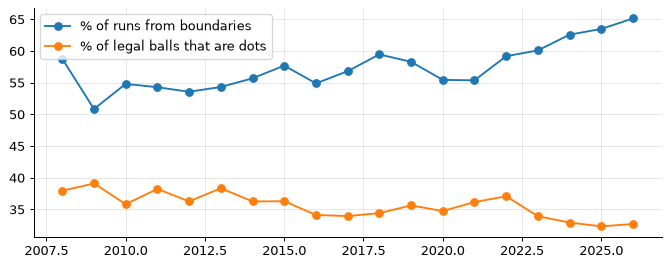

In [17]:
dots = (d.legal_delivery == 1) & (d.runs_total == 0)
season_b = pd.DataFrame({
    "boundary_run_pct": 100 * (4 * d.is_four + 6 * d.is_six).groupby(d.season).sum() / d.groupby("season").runs_total.sum(),
    "dot_ball_pct": 100 * dots.groupby(d.season).sum() / d.groupby("season").legal_delivery.sum()})
total_boundary = 100 * (4 * d.is_four.sum() + 6 * d.is_six.sum()) / d.runs_total.sum()
print(f"Fours {int(d.is_four.sum()):,}, sixes {int(d.is_six.sum()):,} (non-boundary fours and sixes excluded: "
      f"{int(((d.runs_batter.isin([4, 6])) & d.non_boundary).sum())}); boundaries give {total_boundary:.1f}% of all runs; "
      f"dot balls are {100 * dots.sum() / d.legal_delivery.sum():.1f}% of legal balls.")
r = stats.spearmanr(season_b.index, season_b.dot_ball_pct)
print(f"Dot-ball share against season: Spearman rho = {r.statistic:.2f} (n = {len(season_b)} seasons).")
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(season_b.index, season_b.boundary_run_pct, marker="o", label="% of runs from boundaries")
ax.plot(season_b.index, season_b.dot_ball_pct, marker="o", label="% of legal balls that are dots")
ax.legend()
show(fig)

More than half of all runs come from boundaries, and the boundary share has grown in recent seasons while
the share of dot balls has fallen: batters now attack more balls.

### 4.11 Correlations

For completed first innings: total, wickets, legal balls, fours, sixes, powerplay runs and death runs.
Pearson measures linear association; Spearman measures monotone (rank) association.

n = 1,239 completed first innings


,runs,wickets,legal_balls,fours,sixes,powerplay_runs,death_runs
runs,1.0000,-0.5200,0.3200,0.6900,0.7900,0.6000,0.6800
wickets,-0.5200,1.0000,-0.1000,-0.3500,-0.3500,-0.1400,-0.5300
legal_balls,0.3200,-0.1000,1.0000,0.2100,0.0900,-0.0400,0.4700
fours,0.6900,-0.3500,0.2100,1.0000,0.2500,0.4500,0.4500
sixes,0.7900,-0.3500,0.0900,0.2500,1.0000,0.4700,0.5300
powerplay_runs,0.6000,-0.1400,-0.0400,0.4500,0.4700,1.0000,0.1300
death_runs,0.6800,-0.5300,0.4700,0.4500,0.5300,0.1300,1.0000


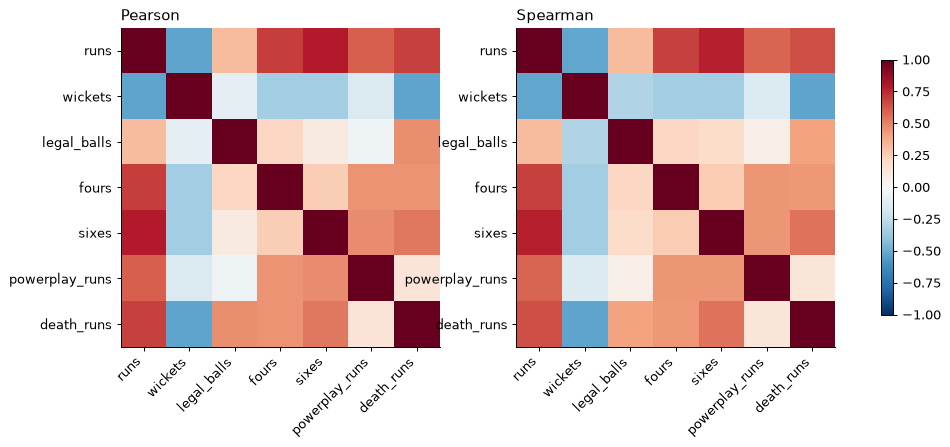

Runs vs sixes: Pearson 0.79, Spearman 0.78; runs vs wickets: Pearson -0.52.


In [18]:
pp_runs = d[d.phase == "powerplay"].groupby(["match_id", "innings"]).runs_total.sum().rename("powerplay_runs")
death_runs = d[d.phase == "death"].groupby(["match_id", "innings"]).runs_total.sum().rename("death_runs")
bnd = d.groupby(["match_id", "innings"])[["is_four", "is_six"]].sum().rename(columns={"is_four": "fours", "is_six": "sixes"})
cf = complete_first.set_index(["match_id", "innings"])[["runs", "wickets", "legal_balls"]].join([bnd, pp_runs, death_runs]).fillna(0)
pearson, spearman = cf.corr(method="pearson"), cf.corr(method="spearman")
print(f"n = {len(cf):,} completed first innings")
display(pearson.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (title, m) in zip(axes, (("Pearson", pearson), ("Spearman", spearman))):
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(m)), m.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(m)), m.index)
    ax.set_title(title, loc="left")
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=.8)
show(fig)
print(f"Runs vs sixes: Pearson {pearson.loc['runs', 'sixes']:.2f}, Spearman {spearman.loc['runs', 'sixes']:.2f}; "
      f"runs vs wickets: Pearson {pearson.loc['runs', 'wickets']:.2f}.")

Totals rise with sixes, fours and powerplay and death scoring, and fall with wickets lost. The Pearson and
Spearman matrices agree in sign, so the associations are not driven by a few extreme innings.

### 4.12 Season trend and a descriptive multiple regression

First, an unweighted straight line through the season means of completed first-innings totals. Second, the
multiple linear regression from the project's Stage 2 analysis: first-innings runs explained by wickets
lost, legal balls and season (minus 2018), on 2018–2025 first innings. It is **descriptive**: it uses
end-of-innings quantities and cannot be used to predict a score before the innings ends.

In [19]:
season_means = complete_first.groupby("season").runs.mean()
trend = stats.linregress(season_means.index, season_means.values)
print(f"Season-mean trend: {trend.slope:+.2f} runs per season, R² = {trend.rvalue ** 2:.2f}, p = {trend.pvalue:.2g} "
      f"(n = {len(season_means)} seasons).")
from sklearn.linear_model import LinearRegression  # noqa: E402
from sklearn.metrics import mean_absolute_error, r2_score  # noqa: E402

reg_rows = innings[(innings.innings == 1) & innings.season.between(2018, 2025)]
X = reg_rows[["wickets", "legal_balls", "season"]].assign(season=lambda f: f.season - 2018)
lin = LinearRegression().fit(X, reg_rows.runs)
pred = lin.predict(X)
r2 = r2_score(reg_rows.runs, pred)
adj_r2 = 1 - (1 - r2) * (len(X) - 1) / (len(X) - X.shape[1] - 1)


def vif(frame):
    """Variance inflation factor of each column, regressing it on the others with an intercept."""
    out = {}
    for col in frame:
        others = np.column_stack([np.ones(len(frame)), frame.drop(columns=col).to_numpy(float)])
        y = frame[col].to_numpy(float)
        coef, *_ = np.linalg.lstsq(others, y, rcond=None)
        resid = y - others @ coef
        r2_col = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[col] = 1 / (1 - r2_col)
    return pd.Series(out)


print(f"n = {len(X):,}; intercept {lin.intercept_:.2f}; coefficients",
      {k: round(float(v), 3) for k, v in zip(X.columns, lin.coef_)})
print(f"R² = {r2:.3f}, adjusted R² = {adj_r2:.3f}, MAE = {mean_absolute_error(reg_rows.runs, pred):.2f} runs")
print("VIF:", vif(X).round(3).to_dict())
STAGE2 = REPO / "reports" / "stage_02" / "session_01" / "stage02_session01_summary.json"
if STAGE2.is_file():
    stored = json.loads(STAGE2.read_text(encoding="utf-8"))["descriptive_multiple_linear_regression_2018_2025"]
    assert abs(stored["in_sample_r2"] - r2) < 1e-9 and stored["n_first_innings"] == len(X)
    print("Matches the project's Stage 2 regression exactly.")

Season-mean trend: +1.91 runs per season, R² = 0.71, p = 5.9e-06 (n = 19 seasons).


n = 533; intercept 22.55; coefficients {'wickets': -7.786, 'legal_balls': 1.57, 'season': 3.926}
R² = 0.398, adjusted R² = 0.394, MAE = 20.47 runs
VIF: {'wickets': 1.023, 'legal_balls': 1.021, 'season': 1.003}
Matches the project's Stage 2 regression exactly.


Mean first-innings totals have risen over the seasons. In the regression, more wickets lost go with fewer
runs and more balls with more runs, and the season term captures the recent scoring rise. The VIFs are low,
so the coefficients are not distorted by collinearity. Again, this explains finished innings; it is not a
forecast.

## 5. Prediction problems and leakage-free modelling tables

**Task A: next-over wicket.** At the end of each completed over (overs 1–19) of an ordinary innings, predict
whether at least one team wicket falls in the next over. Inputs are what is known at that moment: innings,
completed overs, runs, wickets, run rate, the last over's runs and wickets, both teams, the next over's
phase and the venue. Eligibility: matches with a D/L-marked result are excluded; an over whose length is
anomalous, or any later over in that innings, is excluded; if the next over was cut short **without** a
wicket its outcome is unknown (censored) and the row is dropped, but if a wicket fell before it ended the
outcome is known and the row is kept.

**Task B: batter milestones.** Before a match, predict whether a batter scores under 30, 30–49 or 50+ runs,
given that they bat. One three-class model gives P(30+) = P(30–49) + P(50+) and P(50+), so P(50+) can never
exceed P(30+). Inputs are the batter's form from innings on **strictly earlier dates** only (career, last 5
and last 10 innings, record against this opponent and at this venue, days since the previous innings),
plus the batting team, opponent and venue. D/L-marked and no-result matches are excluded from rows and from
the form histories. Every batter playing on the same day sees the same history cut-off.

In [20]:
DLS = {"D/L", "DLS", "D/L METHOD", "DLS METHOD"}


def phase_for_next_over(completed):
    return "powerplay" if completed <= 5 else "middle" if completed <= 14 else "death"


def build_wicket_table(overs, matches):
    lookup = matches.set_index("match_id")
    rows = []
    for (mid, inn), group in overs.groupby(["match_id", "innings"], sort=False):
        group = group.sort_values("over_index")
        meta = lookup.loc[mid]
        dls = str(meta["outcome_method"]).strip().upper() in DLS
        previous_total = previous_wickets = 0
        previous_index, invalid = None, False
        seq = list(group.itertuples(index=False))
        for j, cur in enumerate(seq[:-1]):
            nxt = seq[j + 1]
            if cur.legal_balls > 6 or cur.legal_balls < 0:
                invalid = True
            if not (nxt.over_index == cur.over_index + 1 and (previous_index is None or cur.over_index == previous_index + 1)):
                invalid = True
            if cur.legal_balls == 6 and not dls and not (invalid or nxt.legal_balls > 6 or nxt.legal_balls < 0
                                                          or cur.wickets_after >= 10 or cur.over_index >= 19):
                witnessed = int(nxt.wickets_after > cur.wickets_after)
                if nxt.legal_balls == 6 or witnessed:
                    completed = cur.over_index + 1
                    rows.append({
                        "match_id": mid, "date": cur.date, "season": int(cur.season), "innings": int(inn),
                        "batting_team": cur.batting_team, "bowling_team": cur.bowling_team,
                        "venue_canonical": meta["venue_canonical"], "completed_overs": completed,
                        "runs": int(cur.runs_after), "wickets": int(cur.wickets_after),
                        "run_rate": float(cur.runs_after) / completed,
                        "last_over_runs": int(cur.runs_after - previous_total),
                        "last_over_wickets": int(cur.wickets_after - previous_wickets),
                        "phase": phase_for_next_over(completed), "wicket_next_over": witnessed,
                        "next_over_legal_balls": int(nxt.legal_balls),
                        "label_evidence": "complete_six_legal_deliveries" if nxt.legal_balls == 6 else "observed_wicket_before_short_over_ended"})
            previous_total, previous_wickets, previous_index = int(cur.runs_after), int(cur.wickets_after), cur.over_index
    return pd.DataFrame(rows)


def average(values):
    return float(np.mean(values)) if len(values) else 0.0


def form_features(history, day, opponent, venue):
    """Form from earlier innings only; history holds (date, runs, opponent, venue) tuples."""
    past = [h[1] for h in history]
    vs = [h[1] for h in history if h[2] == opponent]
    at = [h[1] for h in history if h[3] == venue]
    rate = lambda values, t: average([v >= t for v in values])  # noqa: E731
    return {"prior_innings": len(past), "career_avg_runs": average(past), "career_30_rate": rate(past, 30),
            "career_50_rate": rate(past, 50), "recent5_avg_runs": average(past[-5:]),
            "recent5_30_rate": rate(past[-5:], 30), "recent5_50_rate": rate(past[-5:], 50),
            "recent10_avg_runs": average(past[-10:]), "recent10_30_rate": rate(past[-10:], 30),
            "recent10_50_rate": rate(past[-10:], 50), "opposition_prior_innings": len(vs),
            "opposition_avg_runs": average(vs), "opposition_30_rate": rate(vs, 30),
            "venue_prior_innings": len(at), "venue_avg_runs": average(at), "venue_30_rate": rate(at, 30),
            "days_since_previous_innings": min((day - history[-1][0]).days, 3650) if history else 3650}


def eligible_batting(batter_innings, matches):
    b = batter_innings.merge(matches[["match_id", "outcome_method", "outcome_type"]], on="match_id", validate="many_to_one")
    b["date"] = pd.to_datetime(b["date"])
    dls = b.outcome_method.fillna("").astype(str).str.strip().str.upper().isin(DLS)
    no_result = b.outcome_type.fillna("").astype(str).str.lower().str.contains("no result", regex=False)
    return b.loc[~(dls | no_result)].copy(), int(dls.sum()), int((~dls & no_result).sum())


def build_batter_table(batter_innings, matches):
    eligible, _, _ = eligible_batting(batter_innings, matches)
    eligible["milestone_class"] = np.select([eligible.runs >= 50, eligible.runs >= 30], [2, 1], default=0).astype(int)
    history, rows = defaultdict(list), []
    for day, dated in eligible.sort_values(["date", "match_id", "innings", "batter_id"]).groupby("date", sort=True):
        for r in dated.itertuples(index=False):
            rows.append({"match_id": r.match_id, "date": day.strftime("%Y-%m-%d"), "season": int(r.season),
                         "innings": int(r.innings), "batter_id": r.batter_id, "batter": r.batter,
                         "batting_team": r.batting_team, "bowling_team": r.bowling_team,
                         "venue_canonical": r.venue_canonical,
                         **form_features(history[r.batter_id], day, r.bowling_team, r.venue_canonical),
                         "milestone_class": int(r.milestone_class), "reached_30": int(r.reached_30),
                         "reached_50": int(r.reached_50), "actual_runs": int(r.runs)})
        for r in dated.itertuples(index=False):   # today's runs become history only after today's features
            history[r.batter_id].append((day, int(r.runs), r.bowling_team, r.venue_canonical))
    return pd.DataFrame(rows)


wicket_table = through_csv(build_wicket_table(overs, matches), parse_dates=["date"])
batter_table = through_csv(build_batter_table(batter_innings, matches), parse_dates=["date"])
print(f"Wicket rows: {len(wicket_table):,} from {wicket_table.match_id.nunique():,} matches; "
      f"event rate {wicket_table.wicket_next_over.mean():.2%}")
print(f"Batter rows: {len(batter_table):,} from {batter_table.match_id.nunique():,} matches; class shares "
      + ", ".join(f"{k}: {v:.2%}" for k, v in batter_table.milestone_class.value_counts(normalize=True).sort_index().items()))
assert (wicket_table.groupby("match_id")[["date", "season"]].nunique() == 1).all().all()

Wicket rows: 44,161 from 1,220 matches; event rate 27.82%
Batter rows: 18,429 from 1,211 matches; class shares 0: 74.48%, 1: 14.24%, 2: 11.29%


**Optional cross-check** against the project's stored modelling tables: identical row for row when present.

In [21]:
for name, frame in (("wicket", wicket_table), ("batter", batter_table)):
    path = PROCESSED / f"stage03_{name}_full_history_2008_2026.csv"
    if path.is_file():
        stored = pd.read_csv(path, parse_dates=["date"])
        key = ["match_id", "innings", "completed_overs"] if name == "wicket" else ["match_id", "innings", "batter_id"]
        pd.testing.assert_frame_equal(stored.sort_values(key).reset_index(drop=True),
                                      frame[stored.columns].sort_values(key).reset_index(drop=True))
        print(f"{name}: identical to the stored table ({len(stored):,} rows)")
    else:
        print(f"{name}: stored table not found; cross-check skipped")

wicket: identical to the stored table (44,161 rows)


batter: identical to the stored table (18,429 rows)


Both modelling tables are rebuilt exactly. The features never use the outcome being predicted or anything
that happens after the prediction moment: wicket inputs come from overs already completed, batter inputs
from earlier dates.

## 6. Data assumptions for modelling, with evidence

The evaluation folds train on all seasons before an evaluation season: tuning seasons 2018–2020, validation
seasons 2021–2025, and the 2026 test.

In [22]:
from dataclasses import dataclass  # noqa: E402

BASIC_NUM, ADDED_NUM = ["innings", "completed_overs", "runs", "wickets", "run_rate"], ["last_over_runs", "last_over_wickets"]
FORM_NUM = ["prior_innings", "career_avg_runs", "career_30_rate", "career_50_rate", "recent5_avg_runs",
            "recent5_30_rate", "recent5_50_rate", "recent10_avg_runs", "recent10_30_rate", "recent10_50_rate",
            "opposition_prior_innings", "opposition_avg_runs", "opposition_30_rate", "venue_prior_innings",
            "venue_avg_runs", "venue_30_rate", "days_since_previous_innings"]


@dataclass(frozen=True)
class Task:
    name: str
    target: str
    numeric: list
    categorical: list
    keys: list
    classes: tuple

    @property
    def features(self):
        return self.numeric + self.categorical


WICKET = Task("wicket", "wicket_next_over", BASIC_NUM + ADDED_NUM, ["batting_team", "bowling_team", "phase", "venue_canonical"],
              ["match_id", "innings", "completed_overs"], (0, 1))
BATTER = Task("batter", "milestone_class", FORM_NUM, ["batting_team", "bowling_team", "venue_canonical"],
              ["match_id", "innings", "batter_id"], (0, 1, 2))
TASKS = (WICKET, BATTER)
DATA = {"wicket": wicket_table.sort_values(["date", *WICKET.keys]).reset_index(drop=True),
        "batter": batter_table.sort_values(["date", *BATTER.keys]).reset_index(drop=True)}
TUNING_YEARS, VALIDATION_YEARS, TEST_YEAR = (2018, 2019, 2020), (2021, 2022, 2023, 2024, 2025), 2026


def split(data, year):
    train, valid = data.loc[data.season < year], data.loc[data.season == year]
    if train.empty or valid.empty or train.date.max() >= valid.date.min() or set(train.match_id) & set(valid.match_id):
        raise ValueError(f"Invalid temporal or match split for {year}")
    return train, valid


def icc(y, groups):
    """One-way ANOVA intraclass correlation and its F test."""
    f = pd.DataFrame({"y": y.astype(float), "g": groups})
    g = f.groupby("g").y
    n_i, means, n, k = g.size().to_numpy(), g.mean().to_numpy(), len(f), g.ngroups
    msb = np.sum(n_i * (means - f.y.mean()) ** 2) / (k - 1)
    msw = ((f.y - g.transform("mean")) ** 2).sum() / (n - k)
    k0 = (n - np.sum(n_i ** 2) / n) / (k - 1)
    return (msb - msw) / (msb + (k0 - 1) * msw), stats.f.sf(msb / msw, k - 1, n - k)


rows = []
for task in TASKS:
    data = DATA[task.name]
    gaps = [(split(data, y)[1].date.min() - split(data, y)[0].date.max()).days for y in (*TUNING_YEARS, *VALIDATION_YEARS, TEST_YEAR)]
    event = (data[task.target] >= 1).to_numpy()
    inn_groups = (data.match_id.astype(str) + "-" + data.innings.astype(str)).to_numpy()
    icc_inn, p_inn = icc(event, inn_groups)
    shares = data[task.target].value_counts(normalize=True).sort_index()
    floor = np.mean([(split(data, y)[1][task.target] == split(data, y)[0][task.target].mode()[0]).mean() for y in VALIDATION_YEARS])
    unseen = {y: int(sum((~split(data, y)[1][c].isin(split(data, y)[0][c])).sum() for c in task.categorical)) for y in VALIDATION_YEARS}
    rows.append({"task": task.name, "folds": len(gaps), "min_gap_days": min(gaps), "rows_per_match": round(len(data) / data.match_id.nunique(), 2),
                 "icc_event_within_innings": round(icc_inn, 5), "icc_p_value": float(f"{p_inn:.2g}"),
                 "class_shares": " / ".join(f"{v:.2%}" for v in shares), "majority_accuracy_2021_2025": round(floor, 4),
                 "missing_inputs": int(data[task.features].isna().sum().sum()),
                 "unseen_level_rows_2021_2025": unseen})
display(pd.DataFrame(rows).set_index("task").T)
cold = DATA["batter"]
print(f"Batter rows with no earlier innings (defaults 0.0 and 3,650 days): {int((cold.prior_innings == 0).sum())}, "
      f"of which {int(((cold.prior_innings == 0) & (cold.season == 2026)).sum())} in 2026.")

# Drift: each season against all earlier seasons, standardised mean difference of each numeric input
drift = []
for task in TASKS:
    data = DATA[task.name]
    for year in (*VALIDATION_YEARS, TEST_YEAR):
        ref, cur = data[data.season < year], data[data.season == year]
        for col in task.numeric:
            pooled = math.sqrt((ref[col].var() + cur[col].var()) / 2)
            drift.append({"task": task.name, "season": year, "feature": col,
                          "smd": (cur[col].mean() - ref[col].mean()) / pooled if pooled else 0.0})
drift = pd.DataFrame(drift)
worst = drift.loc[drift.groupby("task").smd.apply(lambda s: s.abs().idxmax())]
display(worst.round(3))
rates = pd.DataFrame({t.name: DATA[t.name].groupby("season")[t.target].apply(lambda s: (s >= 1).mean()) for t in TASKS})
chi = {t.name: stats.chi2_contingency(pd.crosstab(DATA[t.name].season, DATA[t.name][t.target] >= 1))[1] for t in TASKS}
print("Event rate by season (wicket; batter 30+): min–max",
      {k: f"{v.min():.1%}–{v.max():.1%} (χ² homogeneity p = {chi[k]:.2g})" for k, v in rates.items()})

task,wicket,batter
folds,9,9
min_gap_days,150,150
rows_per_match,36.2000,15.2200
icc_event_within_innings,-0.0009,0.0221
icc_p_value,0.7100,0.0000
class_shares,72.18% / 27.82%,74.48% / 14.24% / 11.29%
majority_accuracy_2021_2025,0.7165,0.7287
missing_inputs,0,0
unseen_level_rows_2021_2025,"{2021: 179, 2022: 1145, 2023: 318, 2024: 187, ...","{2021: 74, 2022: 475, 2023: 137, 2024: 92, 202..."


Batter rows with no earlier innings (defaults 0.0 and 3,650 days): 736, of which 34 in 2026.


,task,season,feature,smd
52,batter,2021,opposition_prior_innings,0.5880
39,wicket,2026,run_rate,0.8420


Event rate by season (wicket; batter 30+): min–max {'wicket': '26.0%–28.9% (χ² homogeneity p = 0.47)', 'batter': '21.4%–31.2% (χ² homogeneity p = 1.3e-07)'}


| Assumption | Verdict | Evidence (printed above) | Consequence |
|---|---|---|---|
| Chronological order, no leakage | Holds | every fold's training data ends before its evaluation season begins, with no shared match | scores are not inflated by future information |
| Independent rows | Partially holds | wicket events show no detectable clustering within an innings; batter milestones cluster slightly within an innings (small but significant ICC) | whole matches and seasons stay together in every split; uncertainty is reported across seasons |
| Stationary seasons | Violated | the largest standardised shifts (run rate in 2026; batter form counts) are large, and the batter 30+ rate changes significantly across seasons | expanding-window training and season-by-season evaluation measure the effect instead of assuming it away |
| Classes adequately represented | Partially holds | roughly three quarters of rows are in the majority class; always predicting it already scores about 72–73% accuracy | accuracy cannot separate models; Brier score and log loss are used |
| Complete inputs, sensible defaults | Partially holds | no missing inputs; debutants use default values | `prior_innings = 0` lets tree models separate "no history" from a real zero |
| Category levels seen in training | Partially holds | new franchises (2022) and new venues appear in later folds | unseen levels are encoded as all zeros, so those rows rely on the other inputs |

The same evidence, computed more fully (population stability indices, every intraclass correlation and the
eligibility counts), is in the project's assumption analysis; the optional cell below checks the key
numbers against it when it is present.

In [23]:
SUMMARY = REPO / "reports" / "model_benchmark" / "assumptions" / "summary.json"
if SUMMARY.is_file():
    s = json.loads(SUMMARY.read_text(encoding="utf-8"))
    for r in rows:
        t = s["tasks"][r["task"]]
        assert r["min_gap_days"] == t["chronology"]["min_gap_days"]
        assert abs(r["majority_accuracy_2021_2025"] - t["class_balance"]["majority_class_accuracy_mean"]) < 1e-4
        key = "icc_wicket_by_innings" if r["task"] == "wicket" else "icc_30+_by_innings"
        assert abs(r["icc_event_within_innings"] - t["dependence"][key]["icc"]) < 1e-5
    print("Data-assumption evidence matches the project's assumption analysis.")
else:
    print("Assumption analysis not found; cross-check skipped.")

Data-assumption evidence matches the project's assumption analysis.


## 7. The seven algorithms: how they work, their assumptions and the evidence

Every candidate (except the baseline) uses the same preprocessing, fitted inside each training fold:
numeric inputs are median-imputed, categories are one-hot encoded (an unseen category becomes all zeros),
and logistic regression, naive Bayes and the perceptron also standardise the numeric inputs. Each algorithm
has a grid of three settings, tuned on 2018–2020.

| Algorithm | How it works | Main assumptions | Grid (three settings) |
|---|---|---|---|
| **Class-prior baseline** | predicts the training class shares for every row: p̂ₖ = nₖ/n | the base rate is stable from training to the next season | none |
| **Logistic regression** | P(y=1∣x) = σ(β₀ + βᵀx), softmax for three classes, L2 penalty 1/(2C)·‖β‖² | log-odds linear in each numeric input; little collinearity; independent rows; enough events per weight | C ∈ {1.0 (wicket) / 0.25 (batter), 0.05, 4.0} |
| **Decision tree** | recursive axis-aligned splits minimising Gini impurity 1 − Σ pₖ²; a leaf predicts its class shares | no distributional assumption; a few thresholds describe the signal; high variance | depth 3, 5, 8 with 100, 60, 40 rows per leaf |
| **Random forest** | averages 160 trees grown on bootstrap samples with random feature subsets | averaging decorrelated trees lowers variance without adding bias | depth 8/5/12 with 30/60/15 rows per leaf |
| **Histogram gradient boosting** | adds shallow trees stage by stage, each fitted to the gradient of the log loss: F = F₀ + η Σ hₘ; inputs binned (≤ 255 bins) | the signal is a sum of small interactions; binning loses little; learning rate, iteration cap, leaf limit and L2 control overfitting | (leaves, iterations, L2) = (7, 60, 2), (15, 100, 4), (31, 140, 8); learning rate 0.06, 50 rows per leaf |
| **Gaussian naive Bayes** | P(y=k∣x) ∝ πₖ Πⱼ N(xⱼ; μⱼₖ, σ²ⱼₖ) | inputs independent within each class and normally distributed | variance smoothing 0.001, 0.03, 0.2 |
| **Multilayer perceptron** | ReLU hidden layers and a probability output, fitted with Adam on log loss + α‖W‖² | standardised inputs; optimisation reaches a good, seed-insensitive solution within the epoch cap; enough data | (12), α 0.1, 25 epochs; (24), α 1, 35; (32, 12), α 2, 45 |

The cells below test the assumptions that can be checked before the comparison. Evidence that comes from
the comparison itself (variance across seasons, the forest against a single tree, overfitting gaps) is in
Section 9.

In [24]:
from sklearn.linear_model import LogisticRegression  # noqa: E402


def linearity_test(data, feature, event):
    """Nested likelihood-ratio test: a straight line in the feature vs the line plus one indicator per bin."""
    x = data[feature].to_numpy(float)
    y = event.astype(int)
    distinct = np.unique(x)
    if len(distinct) <= 2:
        return np.nan, 0, np.nan
    bins = pd.qcut(x, 10, labels=False, duplicates="drop") if len(distinct) > 10 else np.searchsorted(distinct, x)
    z = ((x - x.mean()) / x.std()).reshape(-1, 1)
    extended = np.column_stack([z, pd.get_dummies(bins, drop_first=True, dtype=float).to_numpy()])

    def loglik(design):
        p = np.clip(LogisticRegression(C=1e10, max_iter=5000).fit(design, y).predict_proba(design)[:, 1], 1e-12, 1 - 1e-12)
        return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

    ones = np.ones((len(z), 1))
    dof = np.linalg.matrix_rank(np.column_stack([ones, extended])) - np.linalg.matrix_rank(np.column_stack([ones, z]))
    lr = max(2 * (loglik(extended) - loglik(z)), 0.0)
    return lr, dof, stats.chi2.sf(lr, dof)


linearity, vifs = [], {}
for task in TASKS:
    dev = DATA[task.name][DATA[task.name].season < TEST_YEAR]
    event = (dev[task.target] >= 1).to_numpy()
    for feature in task.numeric:
        lr, dof, p = linearity_test(dev, feature, event)
        linearity.append({"task": task.name, "feature": feature, "lr_statistic": lr, "dof": dof, "p_value": p})
    vifs[task.name] = vif(dev[task.numeric])
linearity = pd.DataFrame(linearity)
tested = linearity.dropna()
alpha = 0.05 / tested.groupby("task").size()
tested = tested.assign(rejected=tested.p_value < tested.task.map(alpha))
print("Features whose log-odds depart from a straight line (Bonferroni-corrected 5%):",
      tested.groupby("task").rejected.agg(["sum", "size"]).to_dict("index"))
print("Largest VIF:", {k: f"{v.idxmax()} {v.max():.2f}" for k, v in vifs.items()},
      "| features with VIF > 10:", {k: int((v > 10).sum()) for k, v in vifs.items()})
for task in TASKS:
    dev = DATA[task.name][DATA[task.name].season < TEST_YEAR]
    levels = sum(dev[c].nunique() for c in task.categorical)
    weights = (len(task.numeric) + levels + 1) * (1 if task.name == "wicket" else 3)
    events = int(dev[task.target].value_counts().min())
    print(f"{task.name}: {events:,} minority-class events for {weights} logistic weights = {events / weights:.1f} events per weight")

Features whose log-odds depart from a straight line (Bonferroni-corrected 5%): {'batter': {'sum': 17, 'size': 17}, 'wicket': {'sum': 4, 'size': 6}}
Largest VIF: {'wicket': 'completed_overs 19.61', 'batter': 'recent10_avg_runs 50.46'} | features with VIF > 10: {'wicket': 2, 'batter': 7}
wicket: 11,542 minority-class events for 79 logistic weights = 146.1 events per weight
batter: 1,913 minority-class events for 258 logistic weights = 7.4 events per weight


**Logistic regression: violated.** Most numeric inputs do not act linearly on the log-odds (for example the
wicket risk rises steeply only late in an innings), several inputs are strongly collinear (runs and
completed overs; the overlapping career and recent-form averages), and the batter model has fewer than ten
events per weight. The strong penalty chosen in tuning partly compensates.

wicket: largest |skewness| last_over_wickets 1.64; one-hot columns (0/1, never normal): 71
batter: largest |skewness| venue_prior_innings 4.34; one-hot columns (0/1, never normal): 68


,task,class,pairs_with_abs_r_at_least_0.5,largest_abs_r
0,wicket,0,4,0.9260
1,wicket,1,3,0.9187
2,batter,0,45,0.9156
3,batter,1,38,0.8957
4,batter,2,38,0.8895


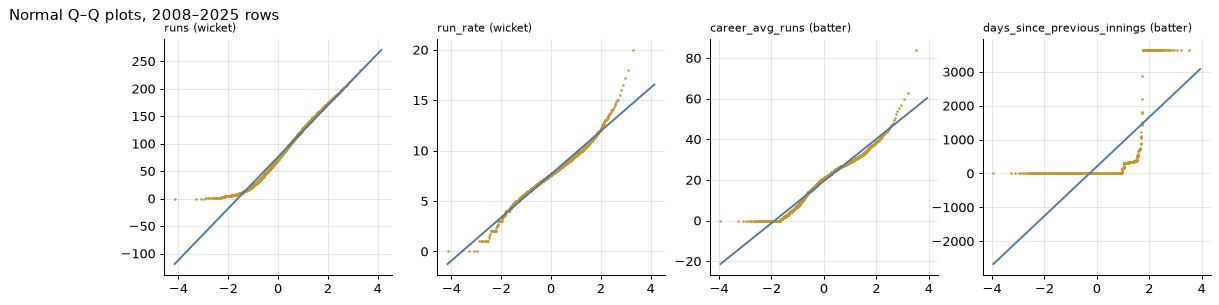

In [25]:
nb_rows = []
for task in TASKS:
    dev = DATA[task.name][DATA[task.name].season < TEST_YEAR]
    for cls in task.classes:
        corr = dev.loc[dev[task.target] == cls, task.numeric].corr().abs().to_numpy()
        np.fill_diagonal(corr, 0)
        nb_rows.append({"task": task.name, "class": cls, "pairs_with_abs_r_at_least_0.5": int((np.triu(corr) >= 0.5).sum()),
                        "largest_abs_r": float(np.nanmax(corr))})
    skew = dev[task.numeric].skew().abs()
    print(f"{task.name}: largest |skewness| {skew.idxmax()} {skew.max():.2f}; one-hot columns (0/1, never normal): "
          f"{sum(dev[c].nunique() for c in task.categorical)}")
display(pd.DataFrame(nb_rows))
qq_features = [("wicket", "runs"), ("wicket", "run_rate"), ("batter", "career_avg_runs"), ("batter", "days_since_previous_innings")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (name, col) in zip(axes, qq_features):
    values = DATA[name].loc[DATA[name].season < TEST_YEAR, col].to_numpy(float)
    (theory, ordered), _ = stats.probplot(values, dist="norm")
    step = max(1, len(ordered) // 2000)
    ax.plot(theory[::step], ordered[::step], ".", ms=2, color="#C8962E")
    ax.plot([theory.min(), theory.max()], [values.mean() + theory.min() * values.std(), values.mean() + theory.max() * values.std()], color="#4C78A8")
    ax.set_title(f"{col} ({name})", loc="left", fontsize=9)
fig.suptitle("Normal Q–Q plots, 2008–2025 rows", x=0.01, ha="left")
show(fig)

**Gaussian naive Bayes: violated.** Inputs are strongly correlated within each class (for example runs and
completed overs), several are far from normal (the Q–Q plots bend away from the straight line, most
clearly for the capped days-since-last-innings), and all one-hot columns are binary. Treating correlated
evidence as independent multiplies it several times, which pushes the probabilities towards 0 and 1; its
calibration is checked in Section 9.

The decision tree and random forest make no distributional assumption; the histogram gradient boosting
model bins numeric inputs into at most 255 bins, so inputs with more distinct values are binned at
quantiles:

In [26]:
for task in TASKS:
    dev = DATA[task.name][DATA[task.name].season < TEST_YEAR]
    distinct = dev[task.numeric].nunique()
    print(f"{task.name}: {int((distinct <= 255).sum())} of {len(distinct)} numeric inputs have at most 255 distinct values "
          f"(binned without loss); the others are binned at quantiles.")

wicket: 6 of 7 numeric inputs have at most 255 distinct values (binned without loss); the others are binned at quantiles.
batter: 7 of 17 numeric inputs have at most 255 distinct values (binned without loss); the others are binned at quantiles.


The perceptron's assumptions (convergence within the epoch cap and insensitivity to the random seed) are
checked after the benchmark in Section 9, where its settings are known.

## 8. Evaluation protocol

1. **Tuning (2018, 2019, 2020).** Each setting is trained on all earlier seasons and scored on each tuning
   season; the setting with the lowest mean Brier score (log loss as tie-break) is frozen.
2. **Ranking (2021–2025).** Each algorithm's frozen setting is trained on all earlier seasons (expanding
   window from 2008) and scored on each of the five seasons. Algorithms are ranked by mean validation Brier
   score, log loss as tie-break. This rule is fixed before the comparison.
3. **Learning curves.** Each ranking fold is also trained on its most recent 10%, 25%, 50% and 75% of
   matches, scored on the same season.
4. **2026 test.** The selected setting is trained on 2008–2025 and scored once on 2026.
5. **Final refit.** The same setting is refitted on all of 2008–2026.

**Metrics.** With yᵢ the outcome and pᵢ the forecast probability:
- **Brier score** = (1/n) Σ (pᵢ − yᵢ)²; for batters, the mean of the 30+ and 50+ Brier scores. Lower is better.
- **Log loss** = −(1/n) Σ log pᵢ(yᵢ), the log of the probability given to what happened. Lower is better.
- **Accuracy**: share of rows whose most probable class happened.
- **Balanced accuracy** = (1/K) Σₖ recallₖ; **macro F1** = (1/K) Σₖ F1ₖ.
- **ROC-AUC**: the probability that a random event row gets a higher forecast than a random non-event row
  (0.5 = no skill); **average precision** summarises the precision–recall curve. For batters both are
  averaged over the 30+ and 50+ events.

**Why Brier is primary.** The output is a probability, so the score must reward honest probabilities. Brier
is a strictly proper scoring rule (minimised only by the true probability), bounded (a single confident
mistake cannot dominate, unlike log loss), and combines calibration and sharpness. Accuracy only looks at
the most probable class; with about three quarters of rows in one class it barely moves between models.

## 9. Results: the seven-algorithm benchmark

The code below builds each candidate pipeline, tunes it on 2018–2020, ranks the tuned candidates on
2021–2025 and fits the learning curves. All fits are single-threaded and seeded, so the results are
deterministic. The perceptron's fixed epoch budget is expected to stop optimisation before scikit-learn's
convergence criterion is met; those convergence warnings are **counted** (not silently hidden) and reported
below. Any other warning would be shown.

In [27]:
from sklearn.compose import ColumnTransformer  # noqa: E402
from sklearn.dummy import DummyClassifier  # noqa: E402
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier  # noqa: E402
from sklearn.exceptions import ConvergenceWarning  # noqa: E402
from sklearn.impute import SimpleImputer  # noqa: E402
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,  # noqa: E402
                             brier_score_loss, confusion_matrix, f1_score, log_loss, roc_auc_score)
from sklearn.naive_bayes import GaussianNB  # noqa: E402
from sklearn.neural_network import MLPClassifier  # noqa: E402
from sklearn.pipeline import Pipeline, make_pipeline  # noqa: E402
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # noqa: E402
from sklearn.tree import DecisionTreeClassifier  # noqa: E402
from threadpoolctl import threadpool_limits  # noqa: E402

TRAIN_FRACTIONS = (0.10, 0.25, 0.50, 0.75, 1.00)
METRICS = ("brier", "log_loss", "accuracy", "balanced_accuracy", "macro_f1", "roc_auc", "average_precision")
MODELS = ["Class-prior baseline", "Logistic regression", "Decision tree", "Random forest",
          "Histogram gradient boosting", "Gaussian naive Bayes", "Multilayer perceptron"]


def search_space(task):
    return {
        "Class-prior baseline": [{}],
        "Logistic regression": [{"C": c} for c in ((1.0 if task.name == "wicket" else 0.25), 0.05, 4.0)],
        "Decision tree": [{"max_depth": 3, "min_samples_leaf": 100}, {"max_depth": 5, "min_samples_leaf": 60},
                          {"max_depth": 8, "min_samples_leaf": 40}],
        "Random forest": [{"max_depth": 8, "min_samples_leaf": 30}, {"max_depth": 5, "min_samples_leaf": 60},
                          {"max_depth": 12, "min_samples_leaf": 15}],
        "Histogram gradient boosting": [{"max_leaf_nodes": 7, "max_iter": 60, "l2_regularization": 2.0},
                                        {"max_leaf_nodes": 15, "max_iter": 100, "l2_regularization": 4.0},
                                        {"max_leaf_nodes": 31, "max_iter": 140, "l2_regularization": 8.0}],
        "Gaussian naive Bayes": [{"var_smoothing": v} for v in (1e-3, 0.03, 0.20)],
        "Multilayer perceptron": [{"hidden_layer_sizes": (12,), "alpha": 0.1, "max_iter": 25},
                                  {"hidden_layer_sizes": (24,), "alpha": 1.0, "max_iter": 35},
                                  {"hidden_layer_sizes": (32, 12), "alpha": 2.0, "max_iter": 45}],
    }


def estimator(task, name, params):
    if name == "Class-prior baseline":
        return DummyClassifier(strategy="prior")
    if name == "Logistic regression":
        names = ("numbers", "categories") if task.name == "wicket" else ("numerics", "categoricals")
        return Pipeline([
            ("features", ColumnTransformer([
                (names[0], Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), task.numeric),
                (names[1], OneHotEncoder(handle_unknown="ignore"), task.categorical)])),
            ("model", LogisticRegression(max_iter=2500 if task.name == "wicket" else 1800, C=params["C"], random_state=42)),
        ])
    if name == "Random forest":
        return Pipeline([
            ("features", ColumnTransformer([("numerics", SimpleImputer(strategy="median"), task.numeric),
                                            ("categoricals", OneHotEncoder(handle_unknown="ignore"), task.categorical)])),
            ("model", RandomForestClassifier(n_estimators=160, n_jobs=1, random_state=42, **params)),
        ])
    models = {"Decision tree": DecisionTreeClassifier(random_state=SEED),
              "Histogram gradient boosting": HistGradientBoostingClassifier(learning_rate=0.06, min_samples_leaf=50,
                                                                            early_stopping=False, random_state=SEED),
              "Gaussian naive Bayes": GaussianNB(),
              "Multilayer perceptron": MLPClassifier(solver="adam", early_stopping=False, n_iter_no_change=46, random_state=SEED)}
    numeric = SimpleImputer(strategy="median")
    if name in {"Gaussian naive Bayes", "Multilayer perceptron"}:
        numeric = make_pipeline(numeric, StandardScaler())
    features = ColumnTransformer([("numeric", numeric, task.numeric),
                                  ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), task.categorical)])
    return make_pipeline(features, models[name].set_params(**params))


CONVERGENCE_WARNINGS = defaultdict(int)


def fit(task, name, params, train):
    model = estimator(task, name, params)
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(train[task.features], train[task.target])
    for w in caught:
        if issubclass(w.category, ConvergenceWarning):
            CONVERGENCE_WARNINGS[(task.name, name)] += 1
        else:  # anything else is unexpected and is shown
            warnings.warn_explicit(str(w.message), w.category, w.filename, w.lineno)
    return model, any(issubclass(w.category, ConvergenceWarning) for w in caught)


def probabilities(task, model, data):
    with threadpool_limits(limits=1):
        p = model.predict_proba(data[task.features])
    assert tuple(model.classes_) == task.classes and np.allclose(p.sum(axis=1), 1, rtol=0, atol=1e-12)
    return p


def event_probabilities(task, y, p):
    if task.name == "wicket":
        return [("wicket", y == 1, np.clip(p[:, 1], 0, 1))]
    return [("30", y >= 1, np.clip(p[:, 1] + p[:, 2], 0, 1)), ("50", y == 2, np.clip(p[:, 2], 0, 1))]


def score(task, data, p):
    y, pred = data[task.target].to_numpy(), p.argmax(axis=1)
    events = {}
    for label, actual, prob in event_probabilities(task, y, p):
        events[f"brier_{label}"] = brier_score_loss(actual, prob)
        events[f"roc_auc_{label}"] = roc_auc_score(actual, prob)
        events[f"average_precision_{label}"] = average_precision_score(actual, prob)
        events[f"observed_rate_{label}"] = float(actual.mean())
        events[f"mean_probability_{label}"] = float(prob.mean())
    mean = lambda prefix: float(np.mean([v for k, v in events.items() if k.startswith(prefix)]))  # noqa: E731
    return {"brier": mean("brier_"), "log_loss": log_loss(y, p, labels=task.classes), "accuracy": accuracy_score(y, pred),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, labels=task.classes, average="macro", zero_division=0),
            "roc_auc": mean("roc_auc_"), "average_precision": mean("average_precision_"), **events}


def recent_matches(train, fraction):
    order = train.drop_duplicates("match_id").sort_values(["date", "match_id"])
    return train.loc[train.date >= order.date.iloc[-math.ceil(fraction * len(order))]]


def run_benchmark(task):
    data = DATA[task.name]
    dev, grids = data[data.season < TEST_YEAR], search_space(task)
    tuning, choices = [], {}
    for name, grid in grids.items():
        trials = []
        for setting, params in enumerate(grid):
            for year in TUNING_YEARS:
                train, valid = split(dev, year)
                model, _ = fit(task, name, params, train)
                trials.append({"model": name, "setting": setting, "year": year, **score(task, valid, probabilities(task, model, valid))})
        trials = pd.DataFrame(trials)
        ranking = trials.groupby("setting")[["brier", "log_loss"]].mean().reset_index()
        choices[name] = int(ranking.sort_values(["brier", "log_loss", "setting"]).iloc[0].setting)
        tuning.append(trials)
    learning = []
    for name, setting in choices.items():
        for year in VALIDATION_YEARS:
            full, valid = split(dev, year)
            for fraction in TRAIN_FRACTIONS:
                train = recent_matches(full, fraction)
                model, capped = fit(task, name, grids[name][setting], train)
                learning.append({"model": name, "setting": setting, "year": year, "training_fraction": fraction,
                                 "train_matches": train.match_id.nunique(), "epoch_cap": capped,
                                 **{f"train_{k}": v for k, v in score(task, train, probabilities(task, model, train)).items()},
                                 **{f"validation_{k}": v for k, v in score(task, valid, probabilities(task, model, valid)).items()}})
    return pd.concat(tuning, ignore_index=True), choices, pd.DataFrame(learning)


RESULTS = {}
for task in TASKS:
    tuning, choices, learning = run_benchmark(task)
    validation = learning[learning.training_fraction == 1.0].rename(columns=lambda c: c.replace("validation_", ""))
    summary = validation.groupby(["model", "setting"])[list(METRICS)].agg(["mean", "std"])
    summary.columns = [f"{m}_{s}" for m, s in summary.columns]
    summary = summary.reset_index().sort_values(["brier_mean", "log_loss_mean", "model"]).reset_index(drop=True)
    RESULTS[task.name] = {"tuning": tuning, "choices": choices, "learning": learning, "validation": validation, "summary": summary}
print("Perceptron fits stopped by the epoch cap (tuning + learning curves):",
      {f"{k[0]} / {k[1]}": v for k, v in CONVERGENCE_WARNINGS.items()})

Perceptron fits stopped by the epoch cap (tuning + learning curves): {'wicket / Multilayer perceptron': 34, 'batter / Multilayer perceptron': 34}


The convergence warnings above all come from the perceptron: every one of its fits reached the fixed epoch
budget before scikit-learn's stopping criterion. The reported perceptron results therefore describe
finite-budget fits. No other algorithm raised a warning.

**Comparison tables** (mean ± standard deviation over the five validation seasons 2021–2025):

In [28]:
def comparison_table(summary):
    out = pd.DataFrame({"algorithm": summary.model})
    for m in METRICS:
        scale = 100 if m in ("accuracy", "balanced_accuracy") else 1
        digits = 2 if scale == 100 else 5 if m in ("brier", "log_loss") else 4
        out[m] = [f"{a * scale:.{digits}f} ± {b * scale:.{digits}f}" for a, b in zip(summary[f"{m}_mean"], summary[f"{m}_std"])]
    out.index = range(1, len(out) + 1)
    return out


for task in TASKS:
    print(f"\n{task.name.upper()} (accuracy columns in %)")
    display(comparison_table(RESULTS[task.name]["summary"]))
    print("Tuned settings:", {m: search_space(task)[m][s] for m, s in RESULTS[task.name]["choices"].items()})


WICKET (accuracy columns in %)


,algorithm,brier,log_loss,accuracy,balanced_accuracy,macro_f1,roc_auc,average_precision
1,Histogram gradient boosting,0.19579 ± 0.00280,0.57929 ± 0.00625,72.24 ± 0.55,52.86 ± 0.33,0.4881 ± 0.0066,0.6032 ± 0.0114,0.3947 ± 0.0082
2,Random forest,0.19595 ± 0.00276,0.57964 ± 0.00611,72.11 ± 0.46,52.52 ± 0.31,0.4815 ± 0.0068,0.6044 ± 0.0111,0.3926 ± 0.0123
3,Multilayer perceptron,0.19626 ± 0.00286,0.58019 ± 0.00645,71.90 ± 0.72,52.09 ± 1.21,0.4724 ± 0.0242,0.6069 ± 0.0145,0.3901 ± 0.0148
4,Logistic regression,0.19655 ± 0.00308,0.58089 ± 0.00700,71.79 ± 0.60,51.36 ± 0.47,0.4552 ± 0.0124,0.6061 ± 0.0150,0.3878 ± 0.0152
5,Decision tree,0.19677 ± 0.00295,0.58161 ± 0.00648,72.25 ± 0.56,52.85 ± 0.34,0.4878 ± 0.0067,0.5931 ± 0.0076,0.3641 ± 0.0093
6,Class-prior baseline,0.20318 ± 0.00196,0.59637 ± 0.00421,71.65 ± 0.44,50.00 ± 0.00,0.4174 ± 0.0015,0.5000 ± 0.0000,0.2835 ± 0.0044
7,Gaussian naive Bayes,0.22610 ± 0.00794,0.66422 ± 0.02089,67.31 ± 1.07,56.98 ± 0.73,0.5724 ± 0.0079,0.5981 ± 0.0159,0.3819 ± 0.0147


Tuned settings: {'Class-prior baseline': {}, 'Logistic regression': {'C': 0.05}, 'Decision tree': {'max_depth': 3, 'min_samples_leaf': 100}, 'Random forest': {'max_depth': 12, 'min_samples_leaf': 15}, 'Histogram gradient boosting': {'max_leaf_nodes': 7, 'max_iter': 60, 'l2_regularization': 2.0}, 'Gaussian naive Bayes': {'var_smoothing': 0.2}, 'Multilayer perceptron': {'hidden_layer_sizes': (24,), 'alpha': 1.0, 'max_iter': 35}}

BATTER (accuracy columns in %)


,algorithm,brier,log_loss,accuracy,balanced_accuracy,macro_f1,roc_auc,average_precision
1,Histogram gradient boosting,0.13937 ± 0.01157,0.71474 ± 0.05020,72.89 ± 2.75,33.38 ± 0.10,0.2819 ± 0.0060,0.7039 ± 0.0223,0.3279 ± 0.0416
2,Random forest,0.13941 ± 0.01191,0.71406 ± 0.05063,72.87 ± 2.77,33.33 ± 0.00,0.2809 ± 0.0062,0.7058 ± 0.0260,0.3254 ± 0.0382
3,Multilayer perceptron,0.13953 ± 0.01209,0.71642 ± 0.05101,72.87 ± 2.77,33.33 ± 0.00,0.2809 ± 0.0062,0.7092 ± 0.0237,0.3351 ± 0.0387
4,Decision tree,0.14053 ± 0.01201,0.72019 ± 0.05080,72.87 ± 2.77,33.33 ± 0.00,0.2809 ± 0.0062,0.6920 ± 0.0246,0.2949 ± 0.0297
5,Logistic regression,0.14092 ± 0.01086,0.72477 ± 0.04624,72.67 ± 2.95,33.47 ± 0.33,0.2859 ± 0.0071,0.6941 ± 0.0211,0.3195 ± 0.0436
6,Class-prior baseline,0.15203 ± 0.01269,0.77243 ± 0.04979,72.87 ± 2.77,33.33 ± 0.00,0.2809 ± 0.0062,0.5000 ± 0.0000,0.1957 ± 0.0209
7,Gaussian naive Bayes,0.26919 ± 0.01618,2.00935 ± 0.19983,55.24 ± 3.08,43.47 ± 1.98,0.3702 ± 0.0129,0.6904 ± 0.0223,0.3085 ± 0.0360


Tuned settings: {'Class-prior baseline': {}, 'Logistic regression': {'C': 0.05}, 'Decision tree': {'max_depth': 3, 'min_samples_leaf': 100}, 'Random forest': {'max_depth': 8, 'min_samples_leaf': 30}, 'Histogram gradient boosting': {'max_leaf_nodes': 7, 'max_iter': 60, 'l2_regularization': 2.0}, 'Gaussian naive Bayes': {'var_smoothing': 0.2}, 'Multilayer perceptron': {'hidden_layer_sizes': (32, 12), 'alpha': 2.0, 'max_iter': 45}}


**Optional reproducibility check**: the comparison tables, the tuned settings and the selection must match
the project's saved benchmark (`reports/model_benchmark/`) within 1e-9.

In [29]:
BENCH = REPO / "reports" / "model_benchmark"
if BENCH.is_dir():
    selection = json.loads((BENCH / "selection.json").read_text(encoding="utf-8"))
    for task in TASKS:
        saved = pd.read_csv(BENCH / f"{task.name}_comparison.csv")
        mine = RESULTS[task.name]["summary"]
        assert saved.model.tolist() == mine.model.tolist()
        diff = np.abs(saved.drop(columns=["model", "setting"]).to_numpy() - mine[saved.columns.drop(["model", "setting"])].to_numpy()).max()
        assert diff <= 1e-9, diff
        assert selection["tasks"][task.name]["chosen_settings"] == RESULTS[task.name]["choices"]
        print(f"{task.name}: comparison table matches (max |difference| {diff:.1e}); tuned settings match")
else:
    print("Saved benchmark not found; check skipped.")

wicket: comparison table matches (max |difference| 9.8e-17); tuned settings match
batter: comparison table matches (max |difference| 4.4e-16); tuned settings match


### Learning curves and convergence

"Convergence" is examined empirically: as more history is used for training, does the validation score stop
improving, and how far apart do the leading algorithms end up? This is evidence from five seasons, not a
mathematical proof, and it cannot say how the models will do after 2026.

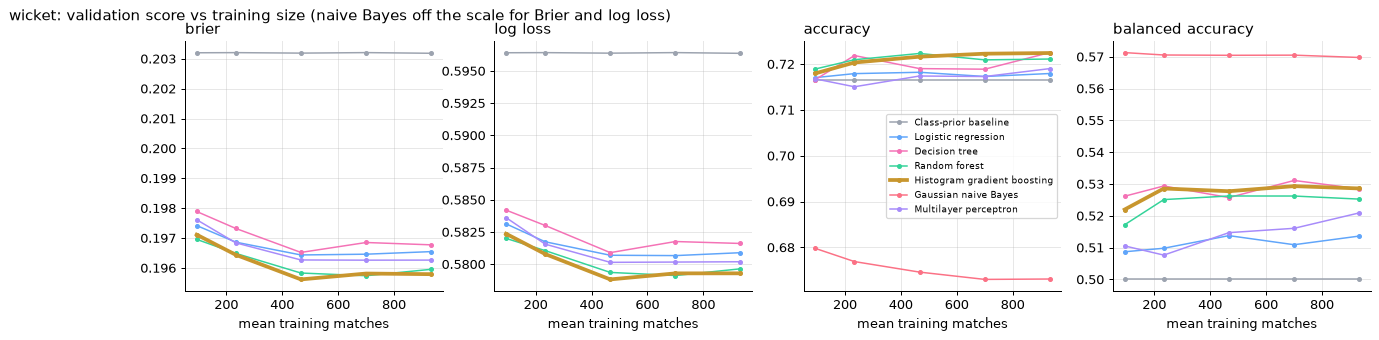

wicket: boosting validation Brier 0.197114, 0.196439, 0.195617, 0.195813, 0.195792 at 10/25/50/75/100%; change 50→75% +0.000196, 75→100% -0.000021. Spread among the top three (Histogram gradient boosting, Random forest, Multilayer perceptron): 0.000657 at 10%, 0.000471 at 100%.


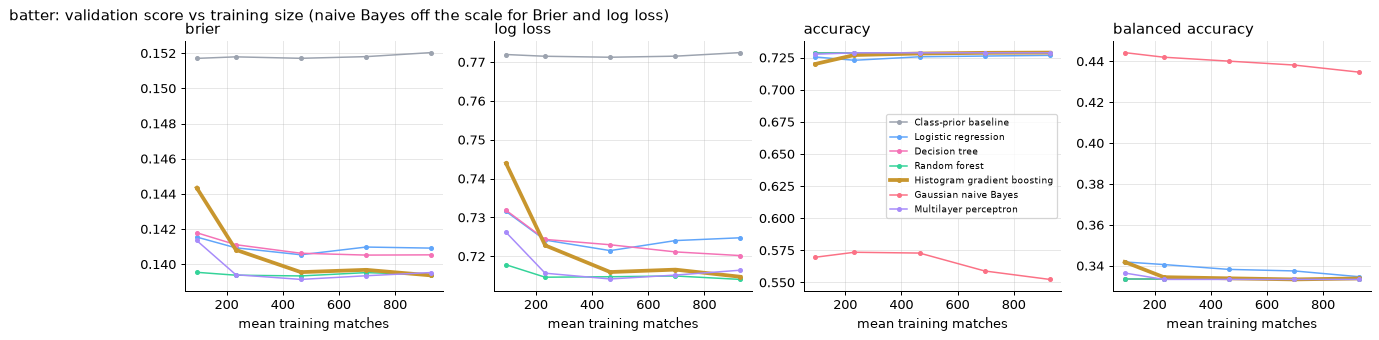

batter: boosting validation Brier 0.144347, 0.140821, 0.139552, 0.139682, 0.139367 at 10/25/50/75/100%; change 50→75% +0.000130, 75→100% -0.000315. Spread among the top three (Histogram gradient boosting, Random forest, Multilayer perceptron): 0.004805 at 10%, 0.000162 at 100%.


In [30]:
colors = {"Class-prior baseline": "#9CA3AF", "Logistic regression": "#60A5FA", "Decision tree": "#F472B6",
          "Random forest": "#34D399", "Histogram gradient boosting": "#C8962E", "Gaussian naive Bayes": "#FB7185",
          "Multilayer perceptron": "#A78BFA"}
for task in TASKS:
    curves = RESULTS[task.name]["learning"].groupby(["model", "training_fraction"]).mean(numeric_only=True).reset_index()
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    for ax, metric in zip(axes, ("brier", "log_loss", "accuracy", "balanced_accuracy")):
        for name in MODELS:
            if name == "Gaussian naive Bayes" and metric in ("brier", "log_loss"):
                continue
            c = curves[curves.model == name]
            ax.plot(c.train_matches, c[f"validation_{metric}"], marker="o", ms=3, color=colors[name],
                    lw=3 if name == "Histogram gradient boosting" else 1.2, label=name)
        ax.set_title(metric.replace("_", " "), loc="left")
        ax.set_xlabel("mean training matches")
    axes[2].legend(fontsize=7)
    fig.suptitle(f"{task.name}: validation score vs training size (naive Bayes off the scale for Brier and log loss)", x=0.01, ha="left")
    show(fig)
    hgb = curves[curves.model == "Histogram gradient boosting"].set_index("training_fraction").validation_brier
    leaders = RESULTS[task.name]["summary"].model.head(3).tolist()
    spread = {f: np.ptp([curves[(curves.model == m) & (curves.training_fraction == f)].validation_brier.iloc[0] for m in leaders])
              for f in TRAIN_FRACTIONS}
    print(f"{task.name}: boosting validation Brier {', '.join(f'{v:.6f}' for v in hgb.values)} at 10/25/50/75/100%; "
          f"change 50→75% {hgb[0.75] - hgb[0.5]:+.6f}, 75→100% {hgb[1.0] - hgb[0.75]:+.6f}. "
          f"Spread among the top three ({', '.join(leaders)}): {spread[0.1]:.6f} at 10%, {spread[1.0]:.6f} at 100%.")

In [31]:
paired_rows = []
for task in TASKS:
    v = RESULTS[task.name]["validation"].pivot(index="year", columns="model", values="brier")
    gaps = v.sub(v["Histogram gradient boosting"], axis=0).drop(columns="Histogram gradient boosting")
    for name in gaps:
        paired_rows.append({"task": task.name, "algorithm": name, "mean_gap": gaps[name].mean(), "sd": gaps[name].std(),
                            "seasons_boosting_better": int((gaps[name] > 0).sum())})
    majority = np.mean([(split(DATA[task.name], y)[1][task.target] == split(DATA[task.name], y)[0][task.target].mode()[0]).mean()
                        for y in VALIDATION_YEARS])
    accs = RESULTS[task.name]["summary"].set_index("model").accuracy_mean
    print(f"{task.name}: majority-class accuracy {majority:.2%}; algorithms within one point of it: "
          f"{int((abs(accs - majority) <= 0.01).sum())} of 7")
display(pd.DataFrame(paired_rows).sort_values(["task", "mean_gap"]).round(6))
variance = []
for task in TASKS:
    full = RESULTS[task.name]["learning"]
    full = full[full.training_fraction == 1.0].groupby("model")[["train_brier", "validation_brier"]].mean()
    full["gap"] = full.validation_brier - full.train_brier
    full["excess_over_baseline"] = full.gap - full.loc["Class-prior baseline", "gap"]
    variance.append(full.assign(task=task.name).reset_index())
display(pd.concat(variance).set_index(["task", "model"]).round(5))

wicket: majority-class accuracy 71.65%; algorithms within one point of it: 6 of 7
batter: majority-class accuracy 72.87%; algorithms within one point of it: 6 of 7


,task,algorithm,mean_gap,sd,seasons_boosting_better
11,batter,Random forest,0.0000,0.0006,2
10,batter,Multilayer perceptron,0.0002,0.0008,4
7,batter,Decision tree,0.0012,0.0005,5
9,batter,Logistic regression,0.0016,0.0009,5
6,batter,Class-prior baseline,0.0127,0.0024,5
8,batter,Gaussian naive Bayes,0.1298,0.0145,5
5,wicket,Random forest,0.0002,0.0003,3
4,wicket,Multilayer perceptron,0.0005,0.0002,5
3,wicket,Logistic regression,0.0008,0.0005,5
1,wicket,Decision tree,0.0010,0.0003,5


train_brier  validation_brier    gap  excess_over_baseline
task   model                                                                                  
wicket Class-prior baseline              0.1998            0.2032 0.0034                0.0000
       Decision tree                     0.1907            0.1968 0.0061                0.0027
       Gaussian naive Bayes              0.2128            0.2261 0.0133                0.0099
       Histogram gradient boosting       0.1895            0.1958 0.0063                0.0029
       Logistic regression               0.1914            0.1966 0.0052                0.0017
       Multilayer perceptron             0.1910            0.1963 0.0053                0.0019
       Random forest                     0.1855            0.1960 0.0105                0.0071
batter Class-prior baseline              0.1402            0.1520 0.0118                0.0000
       Decision tree                     0.1299            0.1405 0.0107               -0.0011
       Gaussian naive Bayes              0.2381            0.2692 0.0311                0.0193
       Histogram gradient boosting       0.1256            0.1394 0.0137                0.0019
       Logistic regression               0.1305            0.1409 0.0104               -0.0014
       Multilayer perceptron             0.1297            0.1395 0.0098               -0.0020
       Random forest                     0.1255            0.1394 0.0139                0.0021

**What the evidence shows.**
- Accuracy alone cannot pick a model: predicting the majority class already gives about 72–73%, and six of
  the seven algorithms are within one percentage point of it. Brier score and log loss separate them.
- Boosting has the lowest mean validation Brier score for both tasks, beats the baseline, logistic
  regression and the single tree in every season, and its learning curve is flat from half of the history
  onwards: more data no longer improves it noticeably (a plateau).
- The top three (boosting, random forest, perceptron) are close. Against the random forest the mean paired
  gap is smaller than its season-to-season standard deviation, and the forest wins some seasons, so the data
  do not show that boosting is better than the forest, only that it is no worse and ranks first under the
  rule fixed in advance.
- Overfitting: boosting's train–validation gap exceeds the class-prior baseline's own gap (which comes from
  season drift, not overfitting) by only a small amount.
- **Decision tree vs random forest** (partially holds / holds): the forest beats the single tree in every
  season, as averaging decorrelated trees should.

**Perceptron and naive Bayes assumptions.** The perceptron is refitted on the 2025 validation fold with five
random seeds, and naive Bayes and boosting calibration is compared on the same fold.

In [32]:
seed_rows, calibration = [], []
for task in TASKS:
    train, valid = split(DATA[task.name][DATA[task.name].season < TEST_YEAR], 2025)
    params = search_space(task)["Multilayer perceptron"][RESULTS[task.name]["choices"]["Multilayer perceptron"]]
    for seed in (42, 1, 2, 3, 4):
        model, capped = fit(task, "Multilayer perceptron", {**params, "random_state": seed}, train)
        seed_rows.append({"task": task.name, "seed": seed, "brier": score(task, valid, probabilities(task, model, valid))["brier"],
                          "stopped_by_epoch_cap": capped})
    for name in ("Gaussian naive Bayes", "Histogram gradient boosting"):
        model, _ = fit(task, name, search_space(task)[name][RESULTS[task.name]["choices"][name]], train)
        _, actual, prob = event_probabilities(task, valid[task.target].to_numpy(), probabilities(task, model, valid))[0]
        idx = np.minimum((prob * 10).astype(int), 9)
        ece = sum((idx == b).mean() * abs(actual[idx == b].mean() - prob[idx == b].mean()) for b in range(10) if (idx == b).any())
        calibration.append({"task": task.name, "model": name, "expected_calibration_error": ece,
                            "share_below_5pct_or_above_95pct": ((prob < .05) | (prob > .95)).mean()})
seeds = pd.DataFrame(seed_rows)
print("Perceptron Brier range across five seeds (2025):", seeds.groupby("task").brier.agg(lambda s: s.max() - s.min()).round(6).to_dict(),
      "| all stopped by the epoch cap:", bool(seeds.stopped_by_epoch_cap.all()))
display(pd.DataFrame(calibration).round(4))

Perceptron Brier range across five seeds (2025): {'batter': 0.001251, 'wicket': 0.000408} | all stopped by the epoch cap: True


,task,model,expected_calibration_error,share_below_5pct_or_above_95pct
0,wicket,Gaussian naive Bayes,0.1306,0.0020
1,wicket,Histogram gradient boosting,0.0094,0.0000
2,batter,Gaussian naive Bayes,0.2952,0.5401
3,batter,Histogram gradient boosting,0.0447,0.0774


The perceptron's assumptions **partially hold**: inputs are standardised, but every fit stopped at the epoch
cap and changing only the random seed moves its Brier score by about as much as (or more than) its gap to
the leader. Naive Bayes is badly calibrated: its expected calibration error is many times boosting's, and a
large share of its batter probabilities sit near 0 or 1, the consequence of its violated independence
assumption.

**Assumption verdicts per algorithm** (from Sections 6, 7 and 9):

| Algorithm | Wicket | Batter | Decisive evidence |
|---|---|---|---|
| Class-prior baseline | Holds | Violated | stable wicket rate; batter 30+ rate changes significantly by season |
| Logistic regression | Violated | Violated | non-linear log-odds, collinearity, few events per weight (batter) |
| Decision tree | Partially holds | Partially holds | the shallowest tree wins tuning; the forest beats it every season |
| Random forest | Holds | Holds | averaging beats the single tree every season |
| Histogram gradient boosting | Holds | Holds | flat learning curve, small excess train–validation gap |
| Gaussian naive Bayes | Violated | Violated | correlated, non-normal and binary inputs; poor calibration |
| Multilayer perceptron | Partially holds | Partially holds | epoch cap reached, seed sensitivity |

## 10. Final selection and the 2026 test

Under the rule fixed in advance (lowest mean validation Brier, log loss as tie-break), **histogram gradient
boosting** is selected for both tasks. It is now trained on 2008–2025 and scored once on 2026.

**Caveat.** The 2026 season had already been examined during the project's earlier development stage, so
this is a retrospective chronological test rather than a first look at unseen data.

In [33]:
HOLDOUT, FINAL_MODELS = {}, {}
for task in TASKS:
    name = RESULTS[task.name]["summary"].model.iloc[0]
    params = search_space(task)[name][RESULTS[task.name]["choices"][name]]
    train, test = split(DATA[task.name], TEST_YEAR)
    model, _ = fit(task, name, params, train)
    p = probabilities(task, model, test)
    prior, _ = fit(task, "Class-prior baseline", {}, train)
    HOLDOUT[task.name] = {"model": name, "params": params, "metrics": score(task, test, p), "p": p, "test": test,
                          "baseline": score(task, test, probabilities(task, prior, test)),
                          "confusion": confusion_matrix(test[task.target], p.argmax(axis=1), labels=task.classes)}
    m, b = HOLDOUT[task.name]["metrics"], HOLDOUT[task.name]["baseline"]
    print(f"{task.name}: {name} {params}; trained on {len(train):,} rows, tested on {len(test):,} rows from {test.match_id.nunique()} matches")
    print(f"   Brier {m['brier']:.5f} (class prior {b['brier']:.5f}), log loss {m['log_loss']:.5f} ({b['log_loss']:.5f}), "
          f"ROC-AUC {m['roc_auc']:.4f}, accuracy {m['accuracy']:.2%}, balanced accuracy {m['balanced_accuracy']:.2%}")
    print("   Confusion matrix (rows actual, columns most probable class):", HOLDOUT[task.name]["confusion"].tolist())

if BENCH.is_dir():
    saved = json.loads((BENCH / "holdout_2026.json").read_text(encoding="utf-8"))
    for task in TASKS:
        diff = max(abs(HOLDOUT[task.name]["metrics"][k] - v) for k, v in saved[task.name]["metrics"].items())
        assert diff <= 1e-9 and saved[task.name]["confusion_matrix"] == HOLDOUT[task.name]["confusion"].tolist()
        forecasts = pd.read_csv(BENCH / f"{task.name}_holdout_forecasts.csv")
        assert np.abs(forecasts[[f"p_class_{c}" for c in task.classes]].to_numpy() - HOLDOUT[task.name]["p"]).max() <= 1e-12
        print(f"{task.name}: 2026 metrics, confusion matrix and every forecast match the saved benchmark (max |difference| {diff:.1e})")

wicket: Histogram gradient boosting {'max_leaf_nodes': 7, 'max_iter': 60, 'l2_regularization': 2.0}; trained on 41,580 rows, tested on 2,581 rows from 73 matches
   Brier 0.19819 (class prior 0.20494), log loss 0.58457 (0.60013), ROC-AUC 0.5995, accuracy 72.03%, balanced accuracy 52.71%
   Confusion matrix (rows actual, columns most probable class): [[1805, 34], [688, 54]]


batter: Histogram gradient boosting {'max_leaf_nodes': 7, 'max_iter': 60, 'l2_regularization': 2.0}; trained on 17,316 rows, tested on 1,113 rows from 72 matches
   Brier 0.15140 (class prior 0.16936), log loss 0.74555 (0.81811), ROC-AUC 0.7177, accuracy 70.44%, balanced accuracy 34.23%
   Confusion matrix (rows actual, columns most probable class): [[778, 0, 7], [160, 0, 1], [161, 0, 6]]
wicket: 2026 metrics, confusion matrix and every forecast match the saved benchmark (max |difference| 0.0e+00)
batter: 2026 metrics, confusion matrix and every forecast match the saved benchmark (max |difference| 0.0e+00)


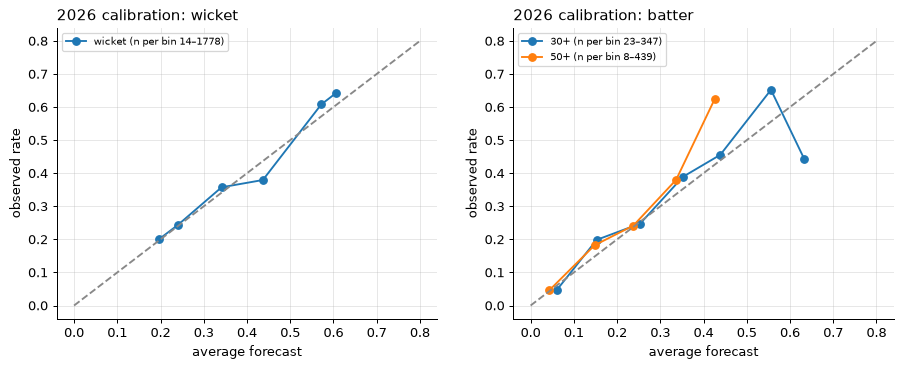

wicket wicket: observed rate 28.75%, mean forecast 28.60%
batter 30: observed rate 29.47%, mean forecast 28.10%
batter 50: observed rate 15.00%, mean forecast 13.15%


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, task in zip(axes, TASKS):
    h = HOLDOUT[task.name]
    for label, actual, prob in event_probabilities(task, h["test"][task.target].to_numpy(), h["p"]):
        idx = np.minimum((prob * 10).astype(int), 9)
        frame = pd.DataFrame({"bin": idx, "actual": actual, "p": prob}).groupby("bin").agg(n=("actual", "size"), obs=("actual", "mean"), pred=("p", "mean"))
        ax.plot(frame.pred, frame.obs, marker="o", label=f"{label}{'+' if label != 'wicket' else ''} (n per bin {frame.n.min()}–{frame.n.max()})")
    ax.plot([0, .8], [0, .8], "--", color="#888")
    ax.set_xlabel("average forecast")
    ax.set_ylabel("observed rate")
    ax.set_title(f"2026 calibration: {task.name}", loc="left")
    ax.legend(fontsize=8)
show(fig)
for task in TASKS:
    m = HOLDOUT[task.name]["metrics"]
    for label in (["wicket"] if task.name == "wicket" else ["30", "50"]):
        print(f"{task.name} {label}: observed rate {m[f'observed_rate_{label}']:.2%}, mean forecast {m[f'mean_probability_{label}']:.2%}")

Boosting beats the class-prior baseline on 2026 for both tasks on Brier score and log loss, and its
forecasts are close to the diagonal in the well-populated bins. The confusion matrices show that the most
probable class is almost always the majority class, which is why accuracy says little here; the useful
output is the probability.

## 11. Final refit through 2026 and illustrative predictions

The selected setting is refitted on every eligible 2008–2026 row. The numbers below are **model outputs for
hypothetical situations, not guarantees**: they are probabilities estimated from past seasons.

In [35]:
for task in TASKS:
    name, params = HOLDOUT[task.name]["model"], HOLDOUT[task.name]["params"]
    FINAL_MODELS[task.name], _ = fit(task, name, params, DATA[task.name])
    print(f"{task.name}: final model trained on {len(DATA[task.name]):,} rows from {DATA[task.name].match_id.nunique():,} matches")

situations = pd.DataFrame([
    {"innings": 1, "completed_overs": 6, "runs": 55, "wickets": 1, "last_over_runs": 12, "last_over_wickets": 0},
    {"innings": 2, "completed_overs": 16, "runs": 140, "wickets": 6, "last_over_runs": 9, "last_over_wickets": 1},
]).assign(batting_team="Mumbai Indians", bowling_team="Chennai Super Kings", venue_canonical="Wankhede Stadium")
situations["run_rate"] = situations.runs / situations.completed_overs
situations["phase"] = situations.completed_overs.map(phase_for_next_over)
situations["P(wicket next over)"] = probabilities(WICKET, FINAL_MODELS["wicket"], situations)[:, 1].round(3)
display(situations[["innings", "completed_overs", "runs", "wickets", "phase", "P(wicket next over)"]])

eligible, _, _ = eligible_batting(batter_innings, matches)
kohli_id = eligible.loc[eligible.batter == "V Kohli", "batter_id"].iloc[0]
past = eligible[eligible.batter_id == kohli_id].sort_values(["date", "match_id", "innings"])
history = [(r.date, int(r.runs), r.bowling_team, r.venue_canonical) for r in past.itertuples(index=False)]
when = pd.Timestamp("2027-04-10")
row = pd.DataFrame([{**form_features(history, when, "Mumbai Indians", "M Chinnaswamy Stadium"),
                     "batting_team": "Royal Challengers Bengaluru", "bowling_team": "Mumbai Indians",
                     "venue_canonical": "M Chinnaswamy Stadium"}])
p = probabilities(BATTER, FINAL_MODELS["batter"], row)[0]
print(f"V Kohli, RCB v Mumbai Indians at M Chinnaswamy Stadium on a future date, after {len(history)} eligible innings: "
      f"P(30+) = {p[1] + p[2]:.3f}, P(50+) = {p[2]:.3f} (model output, conditional on batting).")

wicket: final model trained on 44,161 rows from 1,220 matches


batter: final model trained on 18,429 rows from 1,211 matches


,innings,completed_overs,runs,wickets,phase,P(wicket next over)
0,1,6,55,1,middle,0.2230
1,2,16,140,6,death,0.3460


V Kohli, RCB v Mumbai Indians at M Chinnaswamy Stadium on a future date, after 268 eligible innings: P(30+) = 0.505, P(50+) = 0.331 (model output, conditional on batting).


The wicket probability is higher at the death with six wickets down than early in an innings, as the EDA
would suggest. The batter forecast depends on the player's long record and recent form; it assumes the
player bats and says nothing about selection.

## 12. Conclusions and limitations

**Conclusions.**
- Scoring in the IPL was broadly stable for fifteen seasons and then rose sharply from 2023, driven by more
  sixes and fewer dot balls.
- The death overs are the fastest-scoring phase and have the most wickets; the difference from the
  powerplay is well outside match-to-match variation.
- Chasing has won more often than batting first over the whole archive; the toss is only weakly associated
  with the result.
- For the two prediction tasks, histogram gradient boosting has the lowest mean validation Brier score among
  seven algorithms, its learning curve plateaus, and it beats the class-prior baseline in 2026. Its lead
  over the random forest and the perceptron is small and not distinguishable from season-to-season noise.

**Limitations.**
- The EDA is observational: associations (toss, venue, innings order) are not causal effects.
- Seasons are not stationary; models trained on older seasons may misjudge a new scoring environment.
- Five validation seasons give a rough spread, not a confidence interval.
- D/L-shortened innings and censored overs are excluded, so the wicket forecasts describe ordinary innings.
- The batter forecast is conditional on batting; selection and batting position are not modelled.
- The 2026 test is retrospective (2026 had been examined during development); the final models refitted
  through 2026 have no independent test season yet.

In [36]:
print(f"Total execution time: {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} minutes")

Total execution time: 6.4 minutes
